# Home advantage in the Premier League: a Poisson model, 2015-16 to 2025-26

AM115 mini-project, final report. Alexander van Poecke, David Domanski, Alexia Potter. 16 October 2026.

This notebook is the report. The summary of the findings is printed by the third cell, just below the setup. It runs top to bottom from a clean kernel
(`make notebook`, i.e. `python3 -m nbconvert --to notebook --execute --inplace notebooks/final_report.ipynb`). Every code cell calls
functions in `src/`; every figure is drawn by the cell directly above the text that discusses it;
randomness goes through one `rng = np.random.default_rng(SEED)` (or a seed passed to a `src`
function, printed where it is used). Numbers in the text are rendered from variables or from results
files, never typed by hand.

**What is computed here and what is read.** Cheap things are recomputed live: the per-season
maximum-likelihood fits, the identity γ̂ = ΣH/ΣA, the Skellam check, gradient checks, a 50-replicate
bootstrap demo, the recovery study, the single-split 2024-25 forecast with its paired bootstrap, the
pooled scoreline table and the Dixon–Coles fit. Heavy pieces are read from results files, each written
by a reproducible script:

| file | written by | contents |
|---|---|---|
| `results/numbers.json` | `run_all.py` (`make all`) | 500-replicate bootstrap per season, pooled γ, recovery, preliminary forecast |
| `results/dixon_coles.json` | `scripts/run_dixon_coles.py` | ρ per season and pooled with 1,000-replicate bootstraps, envelopes |
| `results/timeseries.json` | `scripts/run_timeseries.py` | γ 2005-06..2025-26 with 2,000-replicate bootstraps, common-γ tests, crowd flag, block bootstraps, CI coverage |
| `results/rolling.json` | `scripts/run_rolling.py` | rolling-origin forecast evaluation 2016-17..2025-26 |

In [1]:
%matplotlib inline
import os, sys
ROOT = os.getcwd() if os.path.isdir(os.path.join(os.getcwd(), "src")) else os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.insert(0, ROOT)
import numpy as np, pandas as pd
from src import figures as F, report as R, dixon_coles as DC
from src.data import load_matches, CORE_SEASONS
from src.model import make_design, fit_poisson, rates, outcome_probs, negloglik_and_grad
from src.evaluate import log_loss, outcome_to_index
from src.bootstrap import bootstrap_metrics
from src.simulate import recovery_study

SEED = 115
rng = np.random.default_rng(SEED)
F.setup_style()
pd.set_option("display.precision", 4)
print(f"ROOT = {ROOT}\nSEED = {SEED}  (rng = np.random.default_rng(SEED))")

ROOT = /tmp/claude-0/-home-claude/51d94cdf-49e0-518e-999c-8c94335b8a82/scratchpad/pr
SEED = 115  (rng = np.random.default_rng(SEED))


In [2]:
core = load_matches(CORE_SEASONS)
NUM = R.load_results(ROOT, "numbers")
DCR = R.load_results(ROOT, "dixon_coles")
DC_SEASON = pd.read_csv(os.path.join(ROOT, "results", "dixon_coles_by_season.csv")) if DCR else None
for name in ["numbers", "dixon_coles", "timeseries", "rolling"]:
    res = R.load_results(ROOT, name)
    print(f"results/{name}.json: " + (f"generated {res['meta'].get('generated')}" if res else f"MISSING (run {R.RESULT_SOURCES[name]})"))
print(f"{len(core)} matches, {core.season.nunique()} seasons, {core.groupby('season').size().min()}..{core.groupby('season').size().max()} per season")

[data] 2015-16: 380 matches, 20 teams, 2015-08-08 .. 2016-05-17
[data] 2016-17: 380 matches, 20 teams, 2016-08-13 .. 2017-05-21
[data] 2017-18: 380 matches, 20 teams, 2017-08-11 .. 2018-05-13
[data] 2018-19: 380 matches, 20 teams, 2018-08-10 .. 2019-05-12
[data] 2019-20: 380 matches, 20 teams, 2019-08-09 .. 2020-07-26
[data] 2020-21: 380 matches, 20 teams, 2020-09-12 .. 2021-05-23
[data] 2021-22: 380 matches, 20 teams, 2021-08-13 .. 2022-05-22
[data] 2022-23: 380 matches, 20 teams, 2022-08-05 .. 2023-05-28
[data] 2023-24: 380 matches, 20 teams, 2023-08-11 .. 2024-05-19
[data] 2024-25: 380 matches, 20 teams, 2024-08-16 .. 2025-05-25
[data] 2025-26: 380 matches, 20 teams, 2025-08-15 .. 2026-05-24


results/numbers.json: generated 2026-10-13T16:39:27
results/dixon_coles.json: generated 2026-10-13T16:23:48
results/timeseries.json: generated 2026-10-13T16:40:20
results/rolling.json: generated 2026-10-13T16:57:34
4180 matches, 11 seasons, 380..380 per season


In [3]:
R.show_md(R.md_summary(ROOT, NUM))

**Summary.**

- **Home advantage is worth 0.36 [0.33, 0.40] extra home goals per match** (multiplier γ = 1.301 [1.270, 1.337]; common-γ fit over the 20 seasons with crowds, 2005-06..2025-26, 2,000 season-stratified bootstrap refits). It is not constant: it falls by -0.0099 [-0.0142, -0.0055] in log γ per season, about 9% per decade.
- **2020-21, played behind closed doors, had essentially no home advantage**: γ = 1.008 [0.884, 1.143], +0.01 [-0.17, +0.18] extra goals. But 2024-25, with full stadiums, was nearly as low (γ = 1.065 [0.956, 1.187]; random-effects z -3.0 [-5.0, -1.1] vs -2.8 [-4.8, -0.9] for 2020-21), and the within-period closed-doors-minus-full-crowds contrast is -0.108 [-0.247, +0.040], so the data do not show that crowds are the cause.
- **The model forecasts better than any no-model benchmark and slightly worse than the betting market.** Rolling-origin held-out log-loss over the 10 test seasons 2016-17..2025-26 (nats per match, lower is better): uniform 1/3 1.099, prior-seasons base rate 1.066 [1.057, 1.075], Poisson 0.966 [0.951, 0.982], Pinnacle pre-match 0.949 [0.933, 0.966]. Paired: Poisson − base rate -0.100 [-0.114, -0.087] (better in all 10 seasons), Poisson − Pinnacle +0.014 [+0.008, +0.020] (behind in all 10).
- **The Dixon–Coles low-score correction is real but immaterial**: ρ = -0.051 [-0.097, -0.009] (LR p = 0.0216), moving held-out log-loss by -0.0008 [-0.0018, +0.0002] nats per match.
- **Verification**: the fitted γ̂ equals the analytic solution ΣH/ΣA to 3.5e-07 in every season, the score grid matches the Skellam closed form to machine precision, and 95% bootstrap intervals cover the true γ in 0.948 [0.925, 0.966] of simulated seasons.

Every number above is rendered from the results files named in the table below and carries its 95% interval; sections 1–9 follow in the rubric's order.

## 1. Question

**How many extra goals per match does playing at home give a Premier League team, and was that home
advantage lower in 2020-21, when matches were played behind closed doors, than in the other seasons?**

The quantity is the home-advantage multiplier γ in the model of section 3 and its translation into
goals, the mean over matches of λ − λ/γ (the home goals the multiplier adds). The model produces both
with an error bar. A secondary question, needed to trust the model at all: does it forecast match
outcomes better than a forecast that uses no model (the historical home/draw/away frequencies), and how
far is it from the betting market?

Data: football-data.co.uk `E0.csv`, 11 complete seasons, 380 matches each. The first figure shows the
raw outcome shares the question starts from.

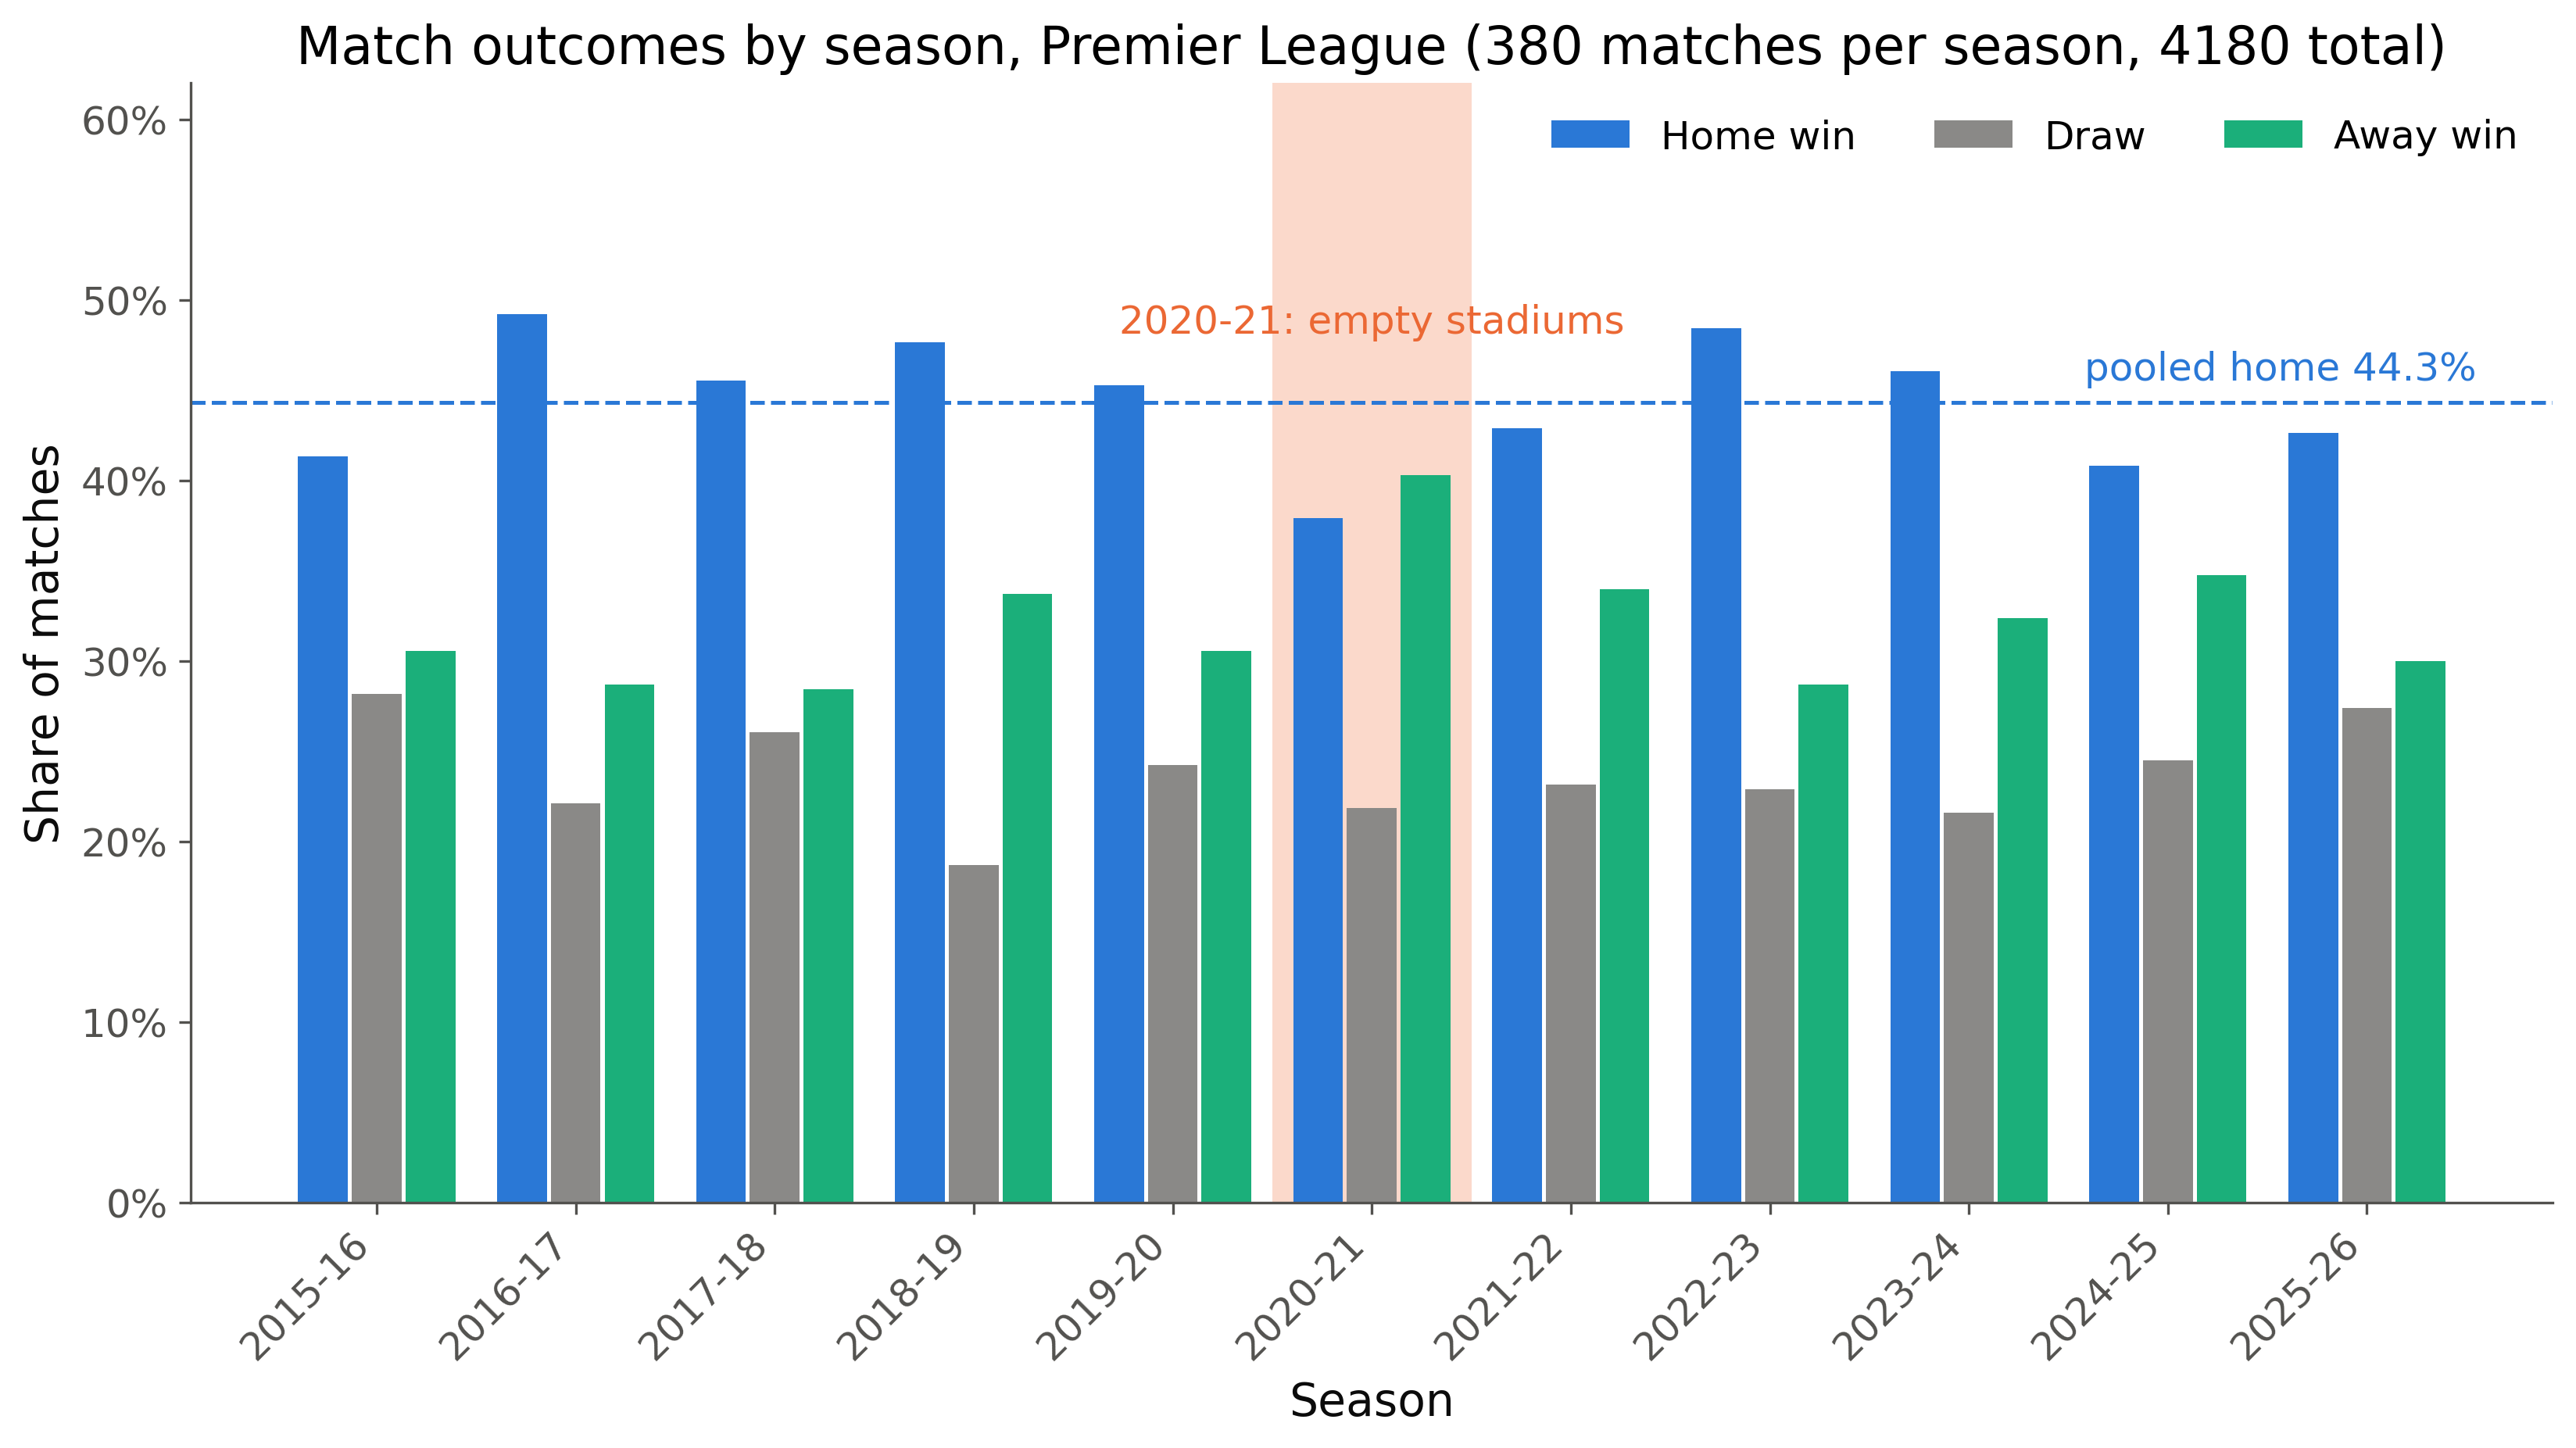

In [4]:
freq, pooled = R.outcome_frequencies(core)
R.show_figure(F.fig1_baselines(freq, pooled))

Figure 1: share of home wins, draws and away wins by season. 2020-21 (shaded) is the only season with
more away wins than home wins. Outcome shares are a crude measure; the model separates the home effect
from who played whom. The answer to the question, from the fits of section 4:

In [5]:
R.show_md(R.md_question(NUM, freq, pooled))

- **Extra home goals per match, 11 seasons pooled:** 0.276 [0.228, 0.326] (γ̂ = 1.217 [1.177, 1.261]; one γ shared by all seasons, season-specific strengths, 500 season-stratified bootstrap refits; this is a common-γ interval).
- **2020-21 (closed doors):** γ̂ = 1.008 [0.877, 1.134], extra home goals 0.011 [-0.178, 0.172] (500 match-resampling refits).
- **Difference 2020-21 minus the mean of the other ten seasons:** -0.236 [-0.374, -0.093] (difference of independent per-season bootstrap draws).
- Home-win share 2020-21 0.379 [0.330, 0.428] vs pooled 0.443 [0.428, 0.458] (binomial normal-approximation intervals).

## 2. Assumptions

**Chosen assumptions** (made on purpose, each tested or bounded below):

1. Goals of the home side X and of the away side Y in a match are Poisson.
2. X and Y are independent given the rates (Dixon–Coles, section 6.3, relaxes this for low scores).
3. Rates are multiplicative: home rate = attack(home) × defensive weakness(away) × γ; away rate =
   attack(away) × defensive weakness(home).
4. One γ for all teams within a season; strengths are constant within a season.
5. One identifiability constraint: geometric mean of attack strengths = 1 per season.

**Implicit assumptions and where each breaks:**

- (i) *Matches are independent*, so the bootstrap resamples matches. Breaks for season-level shocks
  (a manager change, injuries clustered in time); the block and team-cluster bootstraps (section 4,
  results/timeseries.json) check how much this matters.
- (ii) *Strengths are frozen for a whole season.* Breaks visibly when 2023-24 strengths forecast
  2024-25 (numbers below); the rolling-origin evaluation (section 6.2) refits before every matchday.
- (iii) *A promoted team is as strong as the mean of the relegated teams.* Untested by the data until it
  plays; section 6.2 reports three rules.
- (iv) *Crowd status equals the season label.* Breaks for the 2019-20 restart matches and the limited
  crowds of December 2020 and May 2021.
- (v) *The score grid stops at 10 goals a side.* Harmless (numbers below), and probabilities are
  renormalised.
- (vi) *Goals ratio identity.* For a balanced double round robin, γ̂ = ΣH/ΣA exactly (section 3), so the
  40-parameter model adds nothing to the point estimate of γ; it adds the strengths needed to forecast.

In [6]:
R.show_md(R.md_assumption_evidence(core, NUM, DCR, DC_SEASON))

- (iv) crowd status = season label: 92 matches of 2019-20 were played after the 17 June 2020 restart behind closed doors (a count from match dates, no sampling error; attendance itself is not in the data).
- (ii) strengths frozen for a season: the frozen 2023-24 → 2024-25 forecast predicts 1.80 home goals per match against a realised 1.51 [1.38, 1.64] (normal interval of the realised mean, 380 matches), and P(draw) 0.204 against a realised share 0.245 [0.202, 0.288].
- (v) the 0..10 score grid: largest missing mass in 2023-24 is 6.1e-03 per match (exact computation); probabilities are renormalised.
- Poisson variance = mean: Pearson dispersion per season ranges 0.880..1.090 (each season's 95% range under the Poisson model is about [0.899, 1.106]); pooled over 11 seasons 0.948 against a Poisson range [0.969, 1.031]: goals are slightly *under*-dispersed, not over.

## 3. Model

For match m with home team h and away team a:

$$X_m \sim \text{Poisson}(\lambda_m),\quad Y_m \sim \text{Poisson}(\mu_m),\quad X_m \perp Y_m,$$
$$\lambda_m = \alpha_h\,\beta_a\,\gamma,\qquad \mu_m = \alpha_a\,\beta_h .$$

α = attack strength, β = defensive weakness, γ = home-advantage multiplier (γ = 1: no home advantage).
Parameters are estimated on the log scale. The likelihood is unchanged by α → cα, β → β/c and by nothing
else, so one constraint is imposed per season: $\frac{1}{20}\sum_t \log\alpha_t = 0$. That leaves
20 + 20 + 1 − 1 = **40 free parameters per season**. The log-likelihood of a season is

$$\ell(\theta) = \sum_m \big[x_m\log\lambda_m - \lambda_m + y_m\log\mu_m - \mu_m - \log x_m! - \log y_m!\big],$$

maximised with L-BFGS-B and an analytic gradient. Home advantage in goals is
$\frac{1}{M}\sum_m(\lambda_m - \lambda_m/\gamma)$.

**Identity.** The score equations give $\sum_m\lambda_m = \sum_m x_m$ and $\sum_m\mu_m=\sum_m y_m$.
In a double round robin every ordered pair (h, a) appears once, so
$\sum_m \alpha_h\beta_a = \sum_m \alpha_a\beta_h$ and therefore $\hat\gamma = \sum_m x_m / \sum_m y_m$.

**Outcome probabilities.** $P(H)=\sum_{i>j}P(X=i)P(Y=j)$, and similarly for D and A, over 0..10 goals
each side, divided by the grid mass so the three sum to 1. The Skellam closed form for X − Y is a check.

**Dixon–Coles correction** (section 6.3). With one extra parameter ρ,
$P(X=x,Y=y)=\tau(x,y;\lambda,\mu,\rho)\,\text{Pois}(x;\lambda)\,\text{Pois}(y;\mu)$ where
τ = 1 − λμρ for 0-0, 1 + λρ for 0-1, 1 + μρ for 1-0, 1 − ρ for 1-1 and 1 otherwise. The corrections cancel
over the grid, so τ moves probability among the four low cells without changing the total. Admissible
range (all τ ≥ 0): $\max(-1/\lambda,-1/\mu)\le\rho\le\min(1/(\lambda\mu),1)$ for every match; ρ is
fitted jointly with the strengths (analytic gradient, ρ = 0 start) and checked to lie inside this range.
ρ < 0 means more 0-0 and 1-1 and fewer 1-0 and 0-1 than independence gives.

The next cell fits all 11 seasons (about 5 ms each).

In [7]:
fits = R.fit_seasons(core, CORE_SEASONS)
d23, f23 = fits["2023-24"]
print(f"2023-24: {f23.n_params} free parameters, converged = {f23.converged}, gamma-hat = {f23.gamma:.4f}, "
      f"sum(home)/sum(away) = {d23.x.sum() / d23.y.sum():.4f}")

2023-24: 40 free parameters, converged = True, gamma-hat = 1.2171, sum(home)/sum(away) = 1.2171


## 4. Estimation and uncertainty

Every per-season γ̂ is a maximum-likelihood estimate; its 95% interval is a percentile interval from 500
nonparametric bootstrap refits (resample the 380 matches with replacement, refit, warm-started; seed
115 + season index), stored by `run_all.py`. The table puts the live fit next to the stored one to
show they agree.

In [8]:
tab = R.season_table(fits, NUM)
print(f"max |live - stored gamma-hat| = {np.abs(tab.gamma_live - tab.gamma_numbers_json).max():.1e}")
tab

max |live - stored gamma-hat| = 4.7e-11


,gamma_live,gamma_numbers_json,gamma_lo,gamma_hi,ha_goals,ha_goals_lo,ha_goals_hi,n_free_params,converged
season,,,,,,,,,
2015-16,1.2353,1.2353,1.0944,1.3808,0.2842,0.1233,0.4333,40,True
2016-17,1.3282,1.3282,1.1839,1.5061,0.3947,0.2391,0.5630,40,True
2017-18,1.3349,1.3349,1.1960,1.5038,0.3842,0.2388,0.5406,40,True
2018-19,1.2521,1.2521,1.1251,1.3992,0.3158,0.1699,0.4675,40,True
2019-20,1.2576,1.2576,1.1065,1.4469,0.3105,0.1407,0.4963,40,True
2020-21,1.0078,1.0078,0.8769,1.1345,0.0105,-0.1776,0.1720,40,True
2021-22,1.1593,1.1593,1.0278,1.3022,0.2079,0.0384,0.3787,40,True
2022-23,1.3413,1.3413,1.1892,1.5081,0.4158,0.2509,0.5768,40,True
2023-24,1.2171,1.2171,1.0812,1.3551,0.3211,0.1295,0.4905,40,True


The home-advantage figure, drawn from `results/timeseries*` (γ̂ for the 21 seasons 2005-06..2025-26 with 2,000-replicate bootstrap intervals, the common-γ band over the 20 crowd seasons and the random-effects range for one season; `scripts/run_timeseries.py`). If those files are absent the cell falls back to γ̂ for the 11 core seasons from `numbers.json`; it prints which.

src.timeseries.fig2_home_advantage_2005_2026 (results/timeseries*.json|csv)


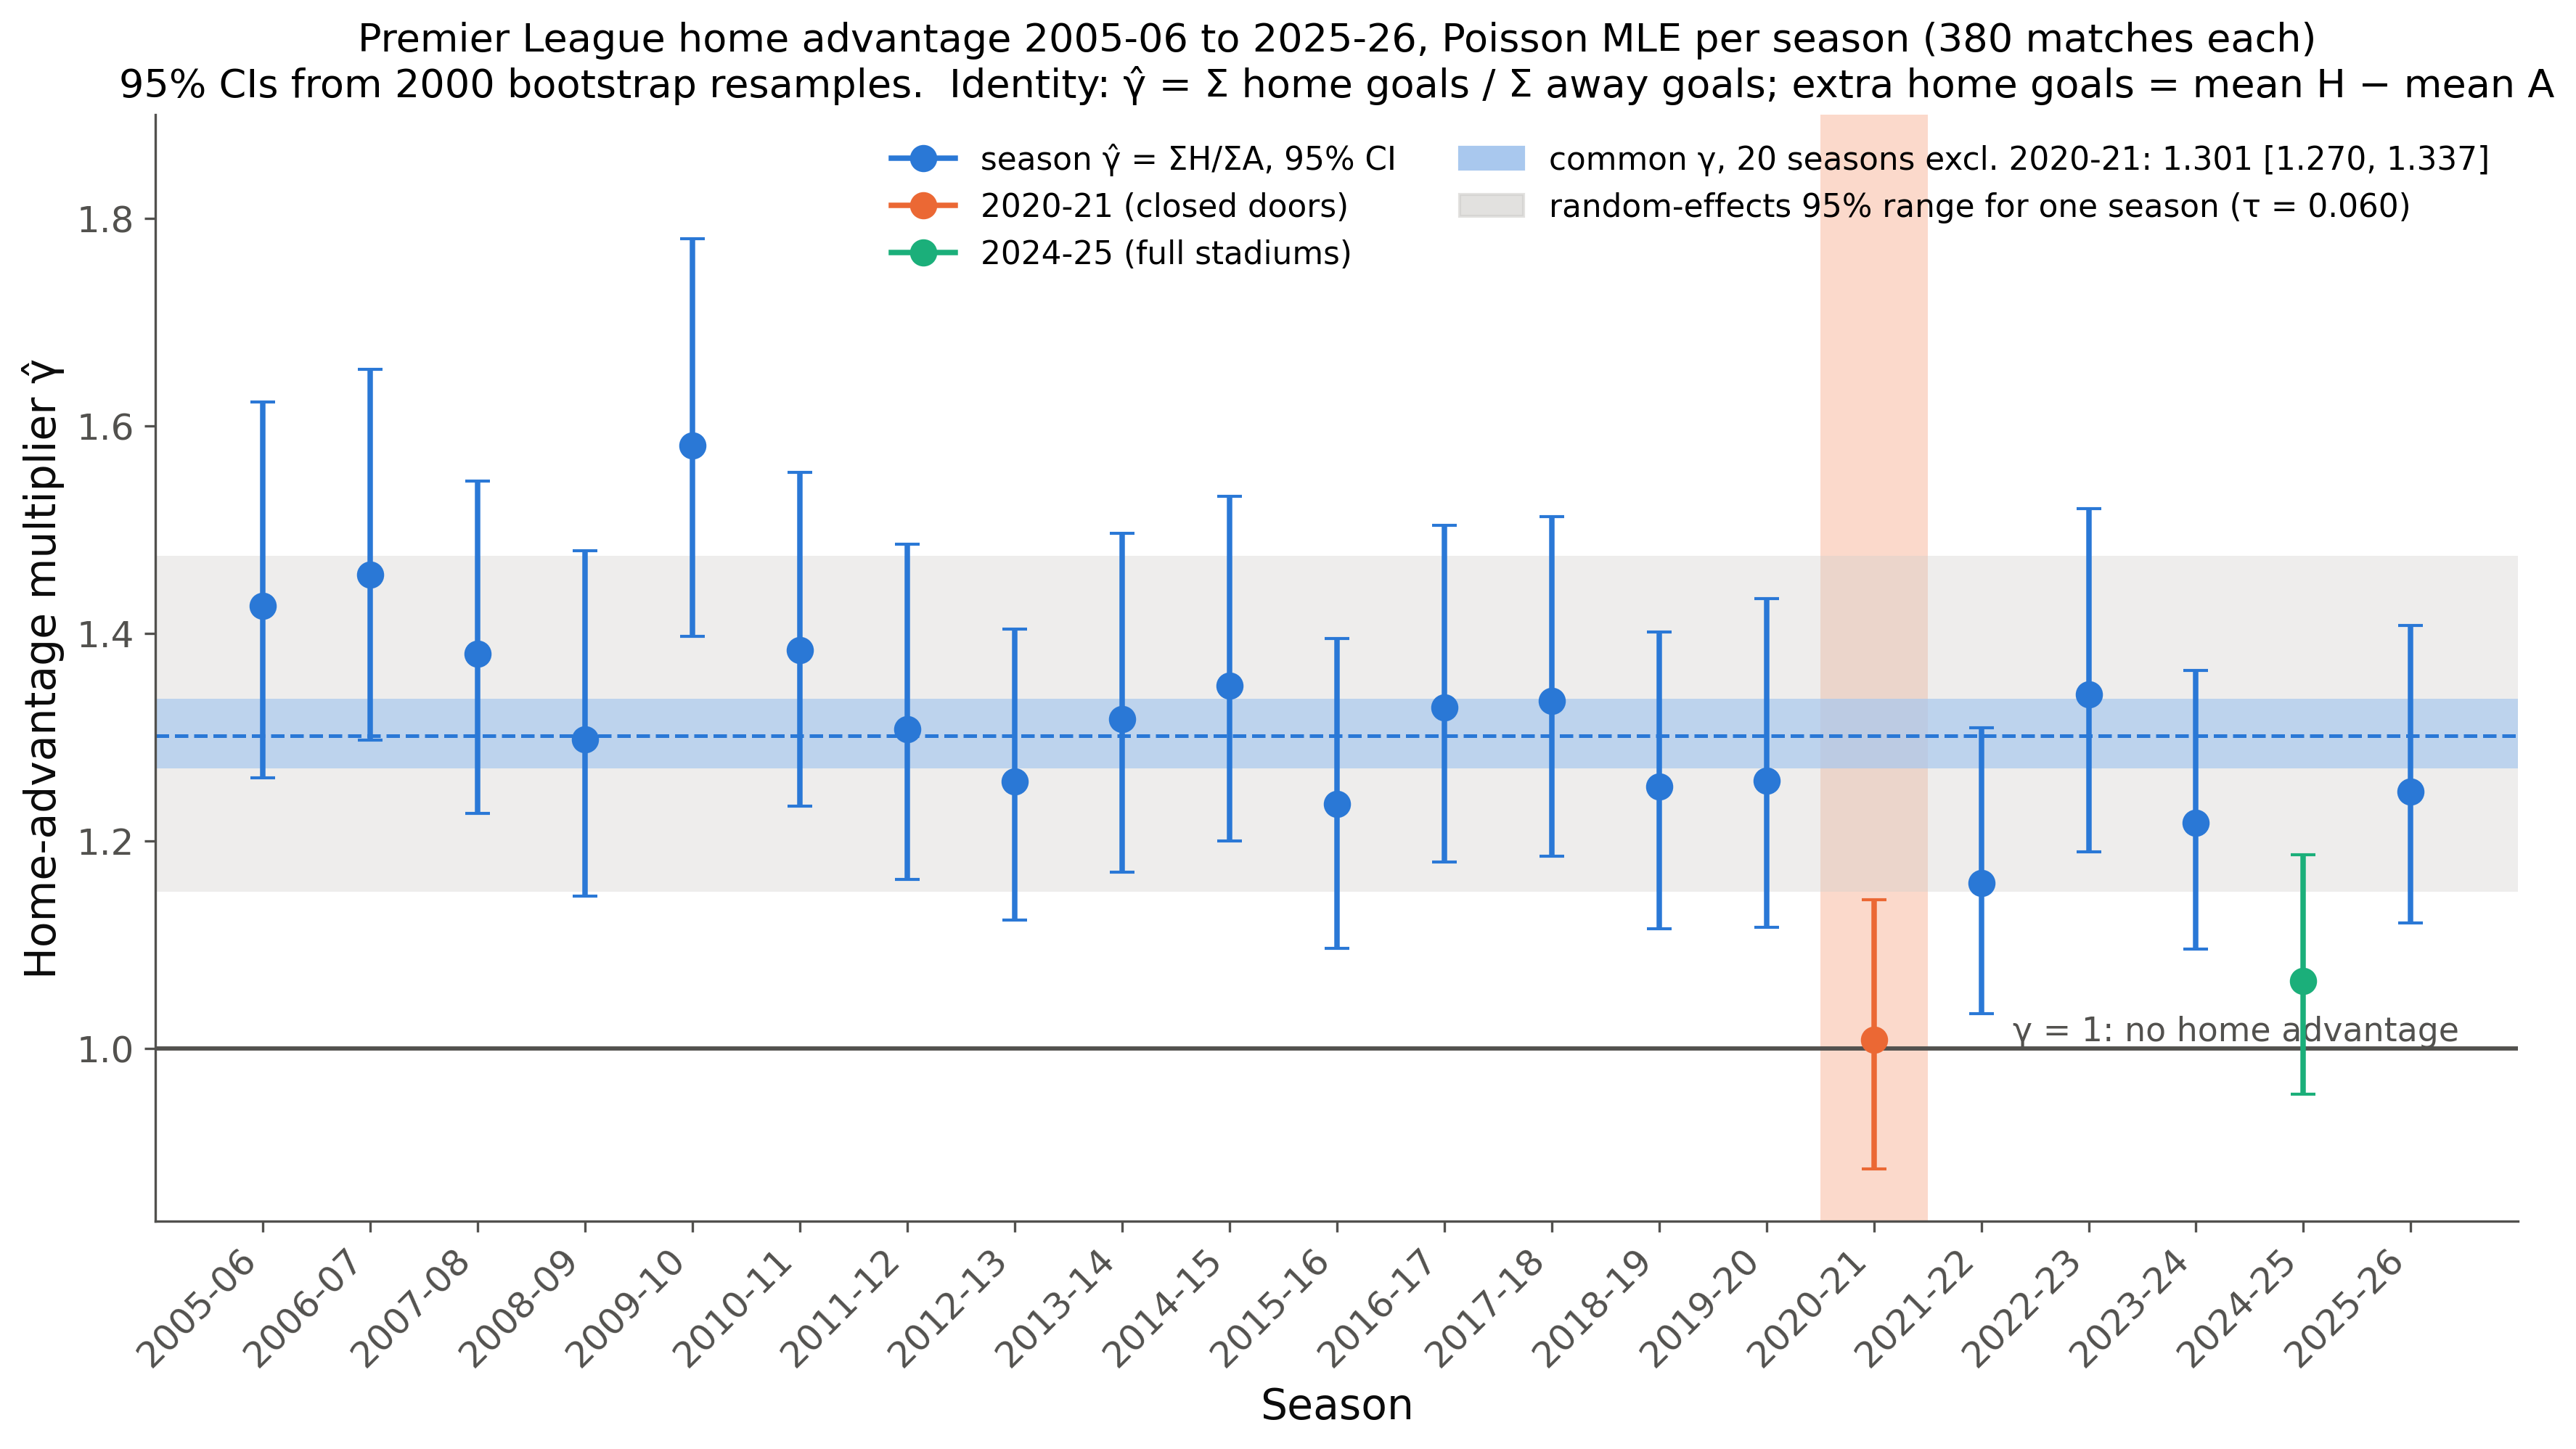

In [9]:
path, how = R.home_advantage_figure(ROOT, NUM)
print(how)
R.show_figure(path)

Figure 2: γ̂ by season with 95% bootstrap intervals and the common-γ band. The extra-goals version of
this figure is the same finding (the identity of section 3 makes extra goals a function of γ̂ and mean
home goals), so the report shows γ only. 2020-21 is the lowest season; 2024-25, with full stadiums, is
nearly as low, which section 8 has to address.

A live bootstrap with the notebook's `rng` (50 replicates, so the interval is rougher than the stored
500-replicate one) shows the interval is reproducible:

In [10]:
demo = R.bootstrap_gamma(*fits["2020-21"], n_boot=50, rng=rng)
print(f"seed {SEED}, 50 replicates")
R.show_md(R.md_estimation(NUM, demo, fits))

seed 115, 50 replicates


- Live 50-replicate bootstrap of 2020-21 γ̂ (seed printed above): 1.008 [0.905, 1.127], SE 0.064; the stored 500-replicate interval is [0.877, 1.134], SE 0.067.
- Common γ over the ten crowd seasons (2020-21 excluded): 1.239 [1.192, 1.285] (500 season-stratified refits).

**Home advantage over time, common-γ tests, crowd flag and resampling schemes** (workstream B, `results/timeseries.json`; every entry: estimate, 95% interval, n, how obtained). The table below is the machine-readable record; the reading of it: among the 10 crowd seasons of 2015-16..2025-26 there is no evidence of between-season variation in γ (Cochran's Q), adding 2020-21 rejects a common γ, and over the 21 seasons since 2005-06 a common γ is rejected even without 2020-21 because home advantage declines by about 9% per decade. 2024-25, played in full stadiums, is about as unusual as 2020-21 under every reference model. Closed doors minus full crowds within 2019-20..2021-22 (flagged by date; attendance is not in the data) is negative with an interval that includes zero. The date-block and team-cluster bootstraps change interval widths by up to about a third in either direction, which is the price of the independent-matches assumption.

In [11]:
R.show_md(R.results_section(ROOT, "timeseries"))

**results/timeseries.json (written by scripts/run_timeseries.py)**  
seed 115, generated 2026-10-13T16:40:20, runtime 1013.2762677669525 s, bootstrap replicates 2000. Workstream B: Premier League home advantage 2005-06..2025-26. Per-season Poisson gamma with bootstrap CIs and the goals-ratio identity check; common-gamma tests; crowd-status fits 2019-20..2021-22 (E0, D1, SP1); date-block and team-cluster bootstraps; CI coverage and cold-start recovery; fit diagnostics. Attendance is not in the data: crowd status is flagged from match dates.

| quantity | estimate | 95% CI | n | how obtained |
|---|---|---|---|---|
| common_gamma_20_crowd_seasons | 1.3013 | [1.2696, 1.3371] | 7600 | pooled MLE, season-specific strengths and one shared gamma over the 20 seasons 2005-06..2025-26 except 2020-21 (= sum H / sum A); common-gamma interval: percentile CI from 2000 season-stratified bootstrap refits |
| common_gamma_21_seasons | 1.2857 | [1.2543, 1.3205] | 7980 | as common_gamma_20_crowd_seasons but all 21 seasons; common-gamma interval |
| gamma_2020_21 | 1.0078 | [0.8836, 1.1434] | 380 | per-season MLE (= sum H / sum A); percentile CI from 2000 iid match-bootstrap refits, seed 120 |
| gamma_2024_25 | 1.0648 | [0.9556, 1.1866] | 380 | per-season MLE (= sum H / sum A); percentile CI from 2000 iid match-bootstrap refits, seed 124 |
| extra_home_goals_2020_21 | 0.0105 | [-0.1708, 0.1808] | 380 | mean(lambda - lambda/gamma) = mean H - mean A (identity); percentile CI from 2000 iid bootstrap refits |
| extra_home_goals_2024_25 | 0.0921 | [-0.0669, 0.2549] | 380 | mean(lambda - lambda/gamma) = mean H - mean A (identity); percentile CI from 2000 iid bootstrap refits |
| extra_home_goals_common_20_crowd_seasons | 0.3595 | [0.3264, 0.3959] | 7600 | pooled common-gamma fit, mean(lambda - lambda/gamma); season-stratified bootstrap percentile CI |
| identity_max_abs_gamma_minus_goals_ratio | 0.0000 | [0.0000, 0.0000] | 21 | max over 21 seasons of \|gamma_hat (L-BFGS-B) - sum home goals / sum away goals\|; 'ci' is [min, max] over seasons, not a confidence interval; pooled fits: max 3.4e-07; extra-goals identity: max 3.8e-07 |
| cochran_q_21_seasons | 52.1925 | [9.5908, 34.1696] | 20 | Cochran's Q on log gamma_hat with bootstrap SEs (2000 reps), df = n = 20, p = 0.0001; 'ci' is the central 95% range of chi2_20 under a common gamma |
| lr_common_gamma_21_seasons | 51.2178 | [9.5908, 34.1696] | 20 | 2 x (sum of per-season log-likelihoods - pooled common-gamma log-likelihood), df = n = 20, p = 0.0001; 'ci' is the central 95% range of chi2_20 under H0 |
| cochran_q_20_crowd_seasons | 37.7419 | [8.9065, 32.8523] | 19 | Cochran's Q on log gamma_hat with bootstrap SEs (2000 reps), df = n = 19, p = 0.0064; 'ci' is the central 95% range of chi2_19 under a common gamma |
| lr_common_gamma_20_crowd_seasons | 35.3352 | [8.9065, 32.8523] | 19 | 2 x (sum of per-season log-likelihoods - pooled common-gamma log-likelihood), df = n = 19, p = 0.0127; 'ci' is the central 95% range of chi2_19 under H0 |
| cochran_q_11_core_seasons | 21.7828 | [3.2470, 20.4832] | 10 | Cochran's Q on log gamma_hat with bootstrap SEs (2000 reps), df = n = 10, p = 0.0163; 'ci' is the central 95% range of chi2_10 under a common gamma |
| lr_common_gamma_11_core_seasons | 22.0355 | [3.2470, 20.4832] | 10 | 2 x (sum of per-season log-likelihoods - pooled common-gamma log-likelihood), df = n = 10, p = 0.0149; 'ci' is the central 95% range of chi2_10 under H0 |
| cochran_q_10_core_crowd_seasons | 12.7722 | [2.7004, 19.0228] | 9 | Cochran's Q on log gamma_hat with bootstrap SEs (2000 reps), df = n = 9, p = 0.1732; 'ci' is the central 95% range of chi2_9 under a common gamma |
| lr_common_gamma_10_core_crowd_seasons | 12.0774 | [2.7004, 19.0228] | 9 | 2 x (sum of per-season log-likelihoods - pooled common-gamma log-likelihood), df = n = 9, p = 0.2090; 'ci' is the central 95% range of chi2_9 under H0 |
| trend_log_gamma_per_season_20_crowd_seasons | -0.0099 | [-0.0142, -0.0055] | 20 | inverse-variance weighted regression of log gamma_hat on season start year (bootstrap SEs), SE inflated by sqrt(residual Q/df) if > 1; p = 7.9e-06; residual Q = 17.8 on 18 df (p = 0.471) |
| trend_log_gamma_per_season_10_core_crowd_seasons | -0.0098 | [-0.0220, 0.0023] | 10 | inverse-variance weighted regression of log gamma_hat on season start year (bootstrap SEs), SE inflated by sqrt(residual Q/df) if > 1; p = 0.11; residual Q = 9.7 on 8 df (p = 0.286) |
| dl_tau_20_crowd_seasons | 0.0603 | [0.0231, 0.1079] | 20 | DerSimonian-Laird between-season SD of log gamma; 95% CI by the Q-profile method (Viechtbauer 2007) |
| dl_tau_21_seasons | 0.0773 | [0.0448, 0.1302] | 21 | DerSimonian-Laird between-season SD of log gamma; 95% CI by the Q-profile method (Viechtbauer 2007) |
| dl_tau_10_core_crowd_seasons | 0.0387 | [0.0000, 0.1142] | 10 | DerSimonian-Laird between-season SD of log gamma; 95% CI by the Q-profile method (Viechtbauer 2007) |
| z_2020_21_common_gamma | -3.8014 | [-5.7614, -1.8414] | 20 | (log gamma_s - fixed-effect mean of 20 other crowd seasons) / sqrt(se_s^2 + se_mean^2), bootstrap SEs; p = 0.0001; 'ci' = z +- 1.96; ratio to common gamma 0.775 [0.679, 0.884] |
| z_2020_21_random_effects | -2.8167 | [-4.7767, -0.8567] | 20 | (log gamma_s - DL random-effects mean of 20 other crowd seasons) / sqrt(se_s^2 + tau^2 + se_mean^2), tau = 0.0603; p = 0.0049; 'ci' = z +- 1.96 |
| z_2020_21_vs_trend | -3.0235 | [-4.9835, -1.0635] | 20 | (log gamma_s - linear-trend prediction for that season from the 20 other crowd seasons) / sqrt(se_s^2 + var(prediction)); trend-predicted gamma 1.238; p = 0.0025; 'ci' = z +- 1.96 |
| z_2024_25_common_gamma | -3.6050 | [-5.5650, -1.6450] | 19 | (log gamma_s - fixed-effect mean of 19 other crowd seasons) / sqrt(se_s^2 + se_mean^2), bootstrap SEs; p = 0.0003; 'ci' = z +- 1.96; ratio to common gamma 0.809 [0.721, 0.908] |
| z_2024_25_random_effects | -3.0315 | [-4.9915, -1.0715] | 19 | (log gamma_s - DL random-effects mean of 19 other crowd seasons) / sqrt(se_s^2 + tau^2 + se_mean^2), tau = 0.0373; p = 0.0024; 'ci' = z +- 1.96 |
| z_2024_25_vs_trend | -2.1446 | [-4.1046, -0.1846] | 19 | (log gamma_s - linear-trend prediction for that season from the 19 other crowd seasons) / sqrt(se_s^2 + var(prediction)); trend-predicted gamma 1.219; p = 0.0320; 'ci' = z +- 1.96 |
| pearson_dispersion_pooled_21_seasons | 0.9585 | [0.8803, 1.0897] | 21 | sum of Pearson X^2 over home and away goals / sum of (760 - 40) over 21 per-season fits; 'ci' is the [min, max] of the per-season dispersions; a Poisson season lies in [0.899, 1.106] with 95% probability (chi2_720/720) |
| crowd_gamma_full_e0 | 1.1765 | [1.0763, 1.2821] | 668 | crowd-status Poisson fit, season-specific strengths 2019-20..2021-22, one gamma per status; percentile CI from 2000 season-stratified bootstrap refits; status flagged by date (attendance not in data) |
| crowd_gamma_closed_e0 | 1.0689 | [0.9568, 1.1921] | 442 | crowd-status Poisson fit, season-specific strengths 2019-20..2021-22, one gamma per status; percentile CI from 2000 season-stratified bootstrap refits; status flagged by date (attendance not in data) |
| crowd_gamma_limited_e0 | 1.2727 | [0.9414, 1.6462] | 30 | crowd-status Poisson fit, season-specific strengths 2019-20..2021-22, one gamma per status; percentile CI from 2000 season-stratified bootstrap refits; status flagged by date (attendance not in data) |
| crowd_gamma_closed_minus_full_e0 | -0.1076 | [-0.2469, 0.0396] | 442 | difference of the two gammas in the same crowd-status fit; percentile CI of the paired bootstrap differences (2000 season-stratified refits) |
| crowd_gamma_limited_minus_full_e0 | 0.0962 | [-0.2496, 0.4825] | 30 | difference of the two gammas in the same crowd-status fit; percentile CI of the paired bootstrap differences (2000 season-stratified refits) |
| crowd_gamma_restart_2019_20_minus_full_e0 | 0.0735 | [-0.1397, 0.3044] | 92 | gamma(92 restart matches of 2019-20) - gamma(full crowds) in a 4-status fit; paired bootstrap percentile CI |
| crowd_gamma_closed_minus_fans_allowed_d1 | -0.0914 | [-0.2475, 0.0585] | 388 | Bundesliga 2019-20..2021-22, closed = restart to end of 2020-21, partial crowds not separated; paired season-stratified bootstrap (2000) percentile CI |
| crowd_gamma_closed_minus_fans_allowed_sp1 | -0.1896 | [-0.3390, -0.0308] | 490 | La Liga 2019-20..2021-22, closed = restart to end of 2020-21, partial crowds not separated; paired season-stratified bootstrap (2000) percentile CI |
| ci_width_iid_2020_21 | 0.2598 | [0.2519, 0.2680] | 2000 | width of the 95% percentile interval of gamma, iid bootstrap (2000 refits); 'ci' is the approx Monte Carlo interval width*exp(+-1.96/sqrt(2(B-1))) |
| ci_width_date_block_38x10_2020_21 | 0.2192 | [0.2125, 0.2261] | 2000 | width of the 95% percentile interval of gamma, date_block_38x10 bootstrap (2000 refits); 'ci' is the approx Monte Carlo interval width*exp(+-1.96/sqrt(2(B-1))) |
| ci_width_team_cluster_home_2020_21 | 0.3364 | [0.3261, 0.3470] | 2000 | width of the 95% percentile interval of gamma, team_cluster_home bootstrap (2000 refits); 'ci' is the approx Monte Carlo interval width*exp(+-1.96/sqrt(2(B-1))) |
| ci_width_iid_2024_25 | 0.2310 | [0.2240, 0.2383] | 2000 | width of the 95% percentile interval of gamma, iid bootstrap (2000 refits); 'ci' is the approx Monte Carlo interval width*exp(+-1.96/sqrt(2(B-1))) |
| ci_width_date_block_38x10_2024_25 | 0.3003 | [0.2911, 0.3098] | 2000 | width of the 95% percentile interval of gamma, date_block_38x10 bootstrap (2000 refits); 'ci' is the approx Monte Carlo interval width*exp(+-1.96/sqrt(2(B-1))) |
| ci_width_team_cluster_home_2024_25 | 0.3040 | [0.2947, 0.3136] | 2000 | width of the 95% percentile interval of gamma, team_cluster_home bootstrap (2000 refits); 'ci' is the approx Monte Carlo interval width*exp(+-1.96/sqrt(2(B-1))) |
| ci_coverage_percentile | 0.9480 | [0.9247, 0.9658] | 500 | share of 500 simulated 2023-24-style seasons (truth gamma = 1.2171) whose 95% bootstrap percentile interval (200 refits) contains the truth; Clopper-Pearson 95% CI |
| ci_coverage_wald_log | 0.9500 | [0.9271, 0.9674] | 500 | share of 500 simulated 2023-24-style seasons (truth gamma = 1.2171) whose 95% Wald on log gamma with bootstrap SE interval (200 refits) contains the truth; Clopper-Pearson 95% CI |
| ci_coverage_analytic | 0.9620 | [0.9413, 0.9770] | 500 | share of 500 simulated 2023-24-style seasons (truth gamma = 1.2171) whose 95% analytic log(H/A) +- 1.96 sqrt(1/H + 1/A) interval (200 refits) contains the truth; Clopper-Pearson 95% CI |
| recovery_gamma_bias_warm_start | 0.0021 | [-0.0071, 0.0113] | 200 | mean(gamma_hat) - true gamma over 200 simulated 2023-24 seasons, fit started at the truth; CI = bias +- 1.96 Monte Carlo SE |
| recovery_gamma_bias_cold_start | 0.0021 | [-0.0071, 0.0113] | 200 | same simulated seasons, fit started at the default x0 (strengths 0, gamma = mean H / mean A); max \|gamma_cold - gamma_warm\| = 6.2e-07 |
| max_abs_theta_all_fits | 3.2389 | [0.0000, 3.2389] | 170937 | largest \|log-parameter\| over every fit in this script (n = number of fits); bound is +-5; 'ci' is [0, max]; no parameter within 1.76 of a bound |
| max_projected_gradient_norm_all_fits | 0.0186 | [0.0000, 0.0186] | 170937 | largest infinity-norm of the box-projected gradient of the negative log-likelihood at the returned optimum, over every fit; 'ci' is [0, max] |

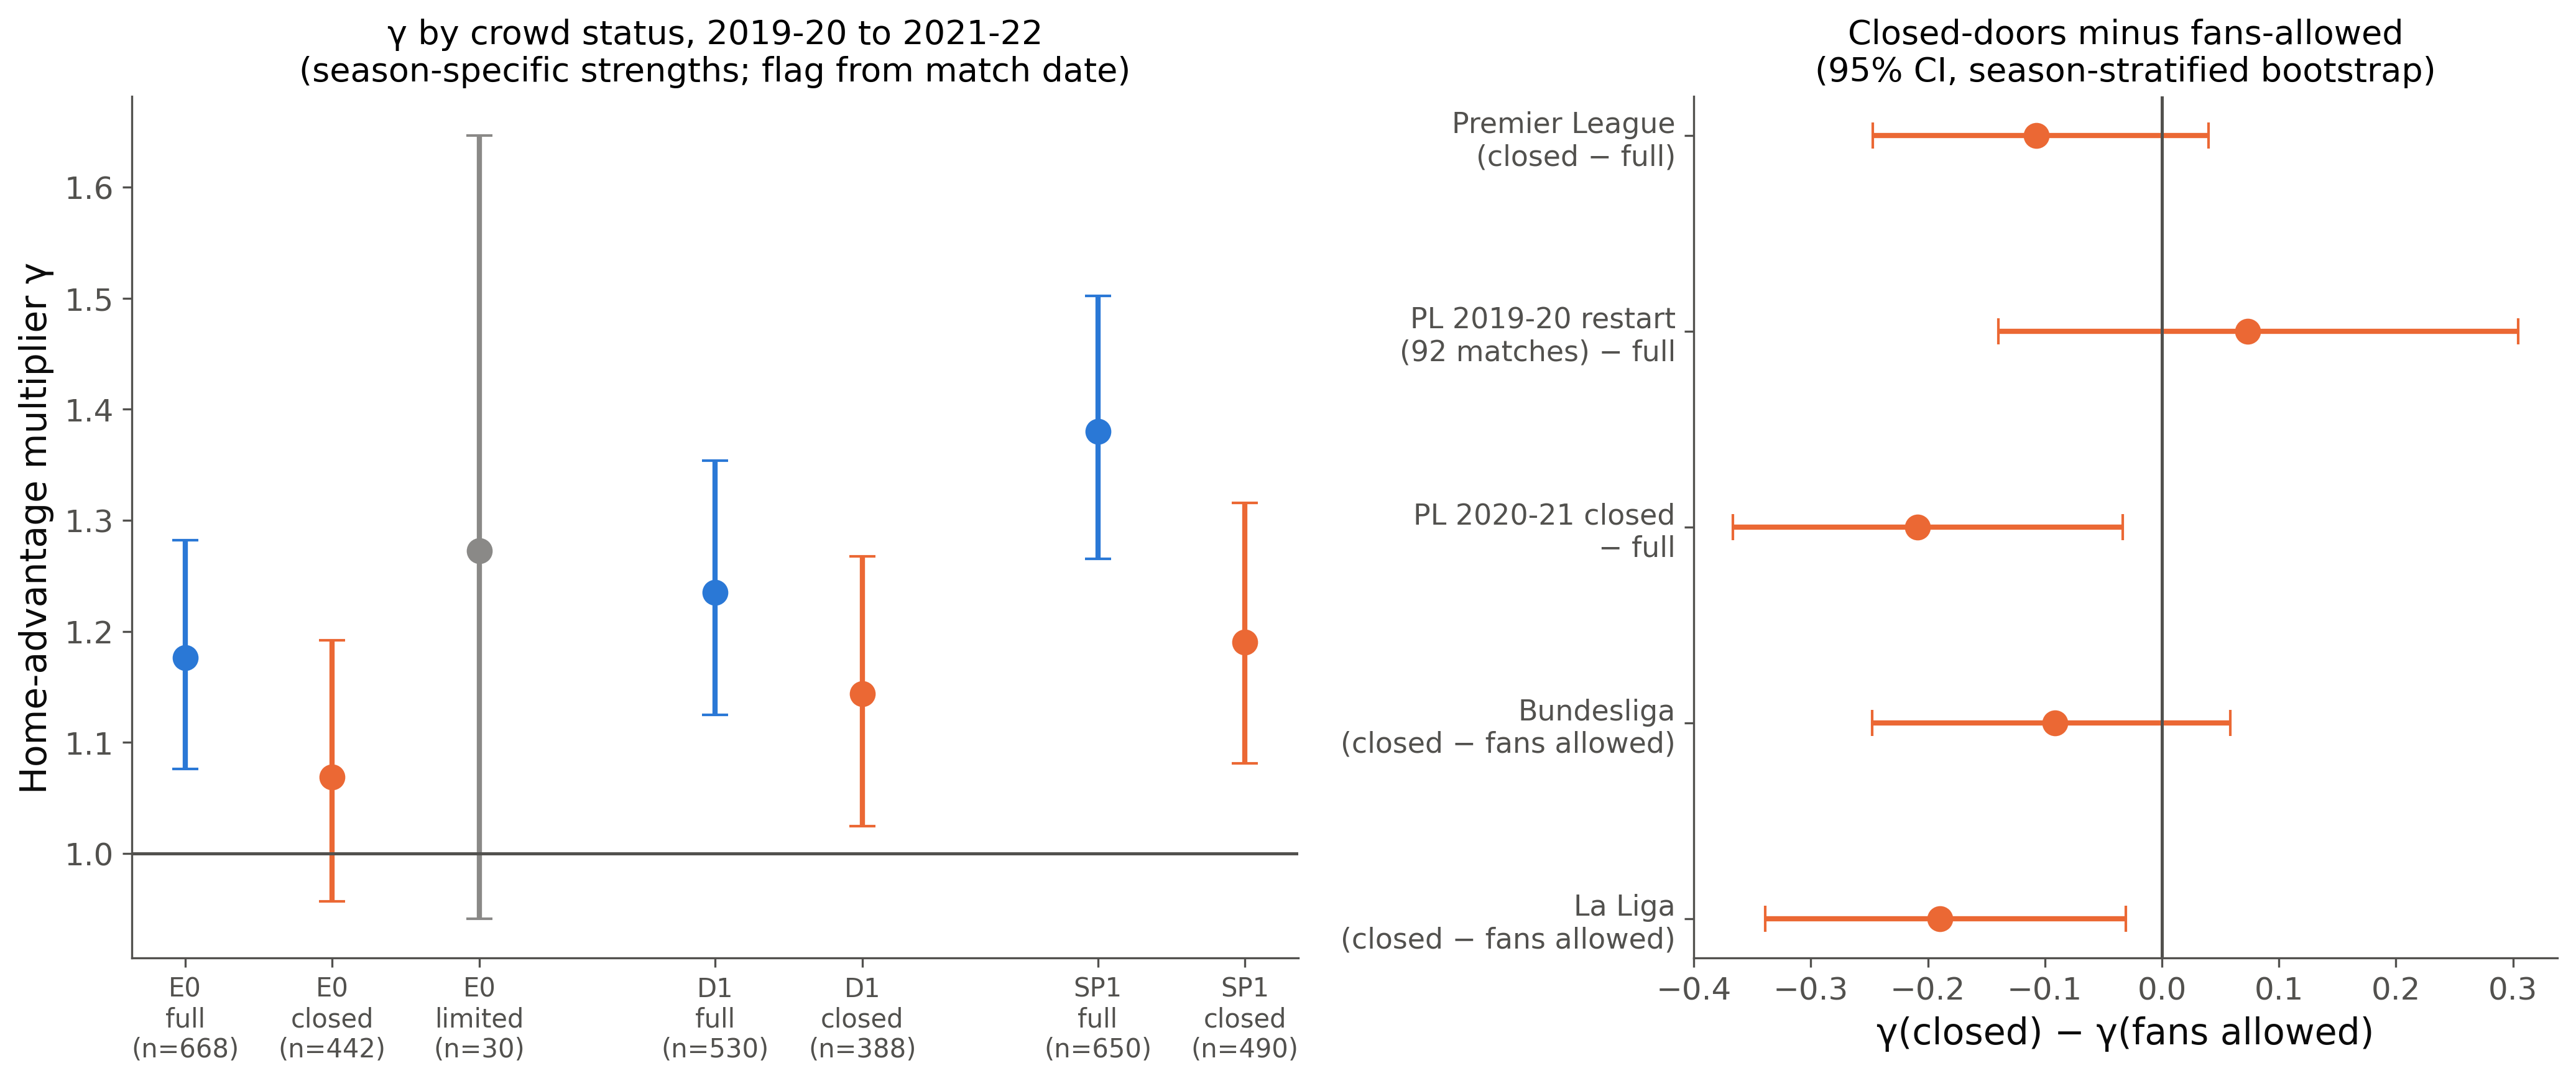

In [12]:
R.show_figure_or_placeholder(R.fig8_from_results(ROOT), "scripts/run_timeseries.py")

Figure 8: γ by crowd status (full, closed doors, limited) for the Premier League, Bundesliga and La Liga over 2019-20..2021-22, season-specific strengths and one γ per status (left), and the closed-minus-fans-allowed differences with 2,000-replicate paired bootstrap intervals (right). The 92 restart matches of 2019-20 show ordinary home advantage; the low value belongs to 2020-21 specifically. The other two leagues point the same way; their partial-crowd dates are not separated, which biases those contrasts toward zero.

## 5. Verification

The code is checked against mathematics whose answer is known: (a) the score-grid outcome probabilities
against the Skellam closed form; (b) the exact identity γ̂ = ΣH/ΣA; (c) analytic against numerical
gradients; (d) the Dixon–Coles factor conserves probability and reduces to the Poisson model at ρ = 0,
and a planted ρ is recovered; (e) planted parameters are recovered from simulated seasons.

In [13]:
sk40, sk10 = R.skellam_check(rng)
ident = R.identity_check(fits)
grad_p = R.poisson_gradient_check(d23, f23, rng)
grad_dc = R.dc_gradient_check(d23, f23, rng)
dc_checks = R.dc_verification(rng, n_boot=50)
ident

,gamma_hat,sum_home_over_sum_away,abs_diff
season,,,
2015-16,1.2353,1.2353,9.2202e-08
2016-17,1.3282,1.3282,3.8334e-08
2017-18,1.3349,1.3349,1.5992e-08
2018-19,1.2521,1.2521,5.4890e-08
2019-20,1.2576,1.2576,3.5292e-07
2020-21,1.0078,1.0078,8.5139e-08
2021-22,1.1593,1.1593,2.1121e-07
2022-23,1.3413,1.3413,6.2699e-08
2023-24,1.2171,1.2171,4.5697e-08


Next, the recovery study: 200 seasons simulated from the fitted 2023-24 parameters on the real fixture
list, each refitted (`src.simulate.recovery_study`, seed 115, the same call as `run_all.py`).

recovery_study seed = 115


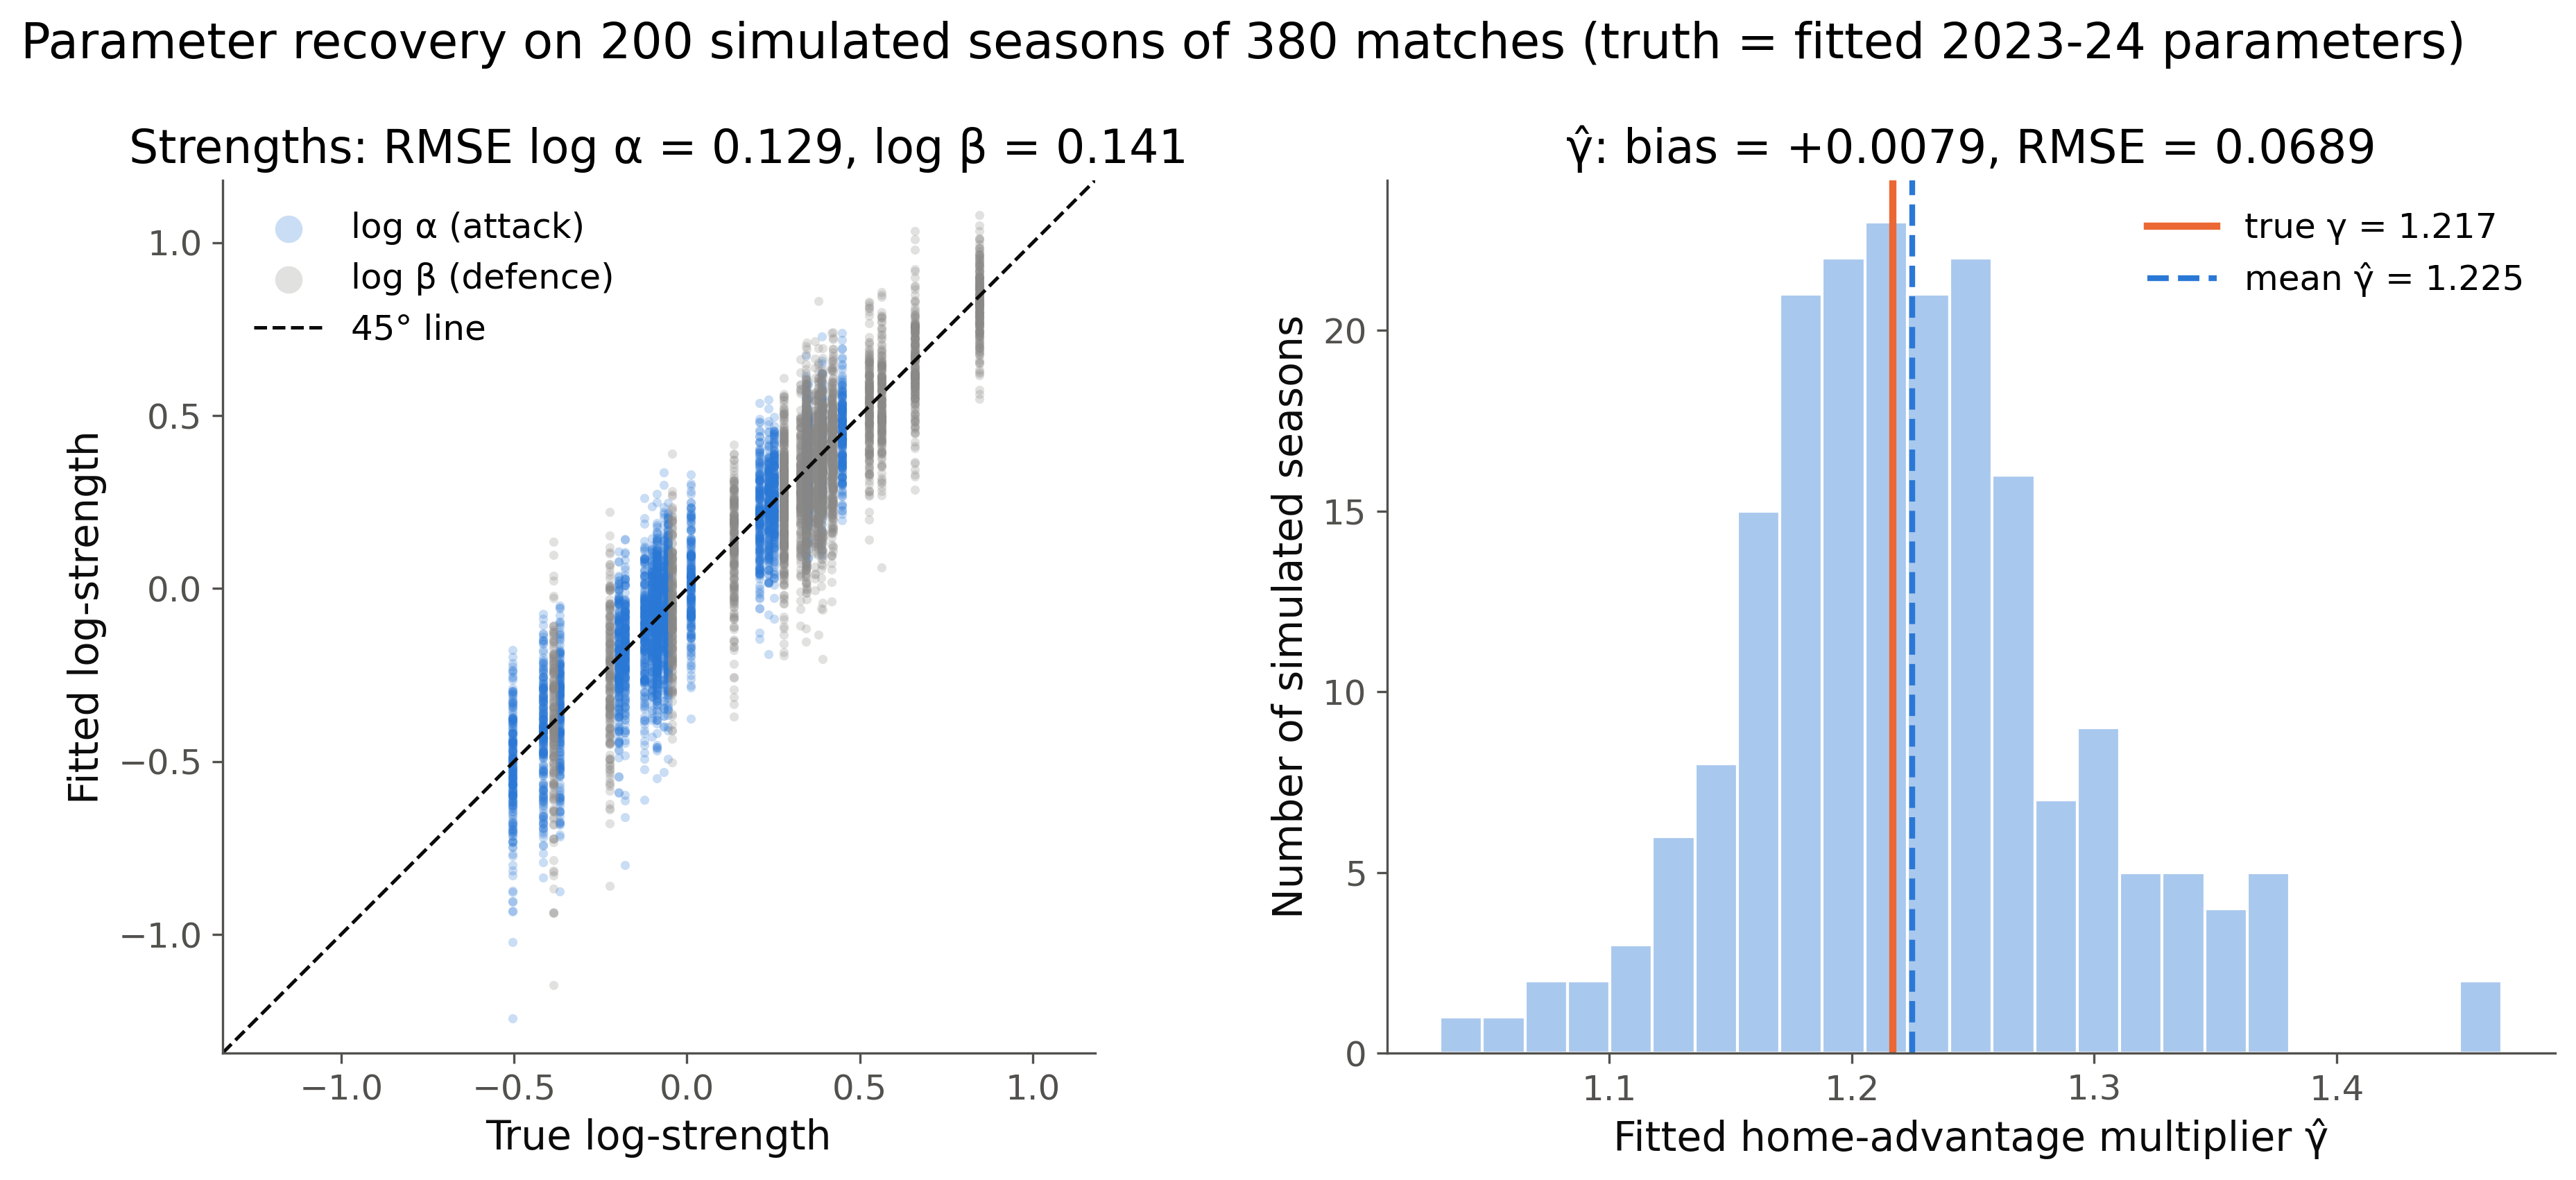

In [14]:
rec = recovery_study(d23, f23.log_alpha, f23.log_beta, f23.log_gamma, n_sims=200, seed=SEED)
rec["truth_label"] = "2023-24"
print(f"recovery_study seed = {SEED}")
R.show_figure(F.fig4_parameter_recovery(rec))

Figure 4: fitted vs true log-strengths over 200 simulated seasons (left) and the distribution of γ̂
(right). All five checks:

In [15]:
R.show_md(R.md_verification(sk40, sk10, ident, grad_p, grad_dc, dc_checks, rec, NUM))

- Score grid vs Skellam closed form (200 random rate pairs): max |difference| 9.4e-16 on a 0..40 grid, 2.8e-03 on the 0..10 grid used (truncation, before renormalising).
- Identity γ̂ = ΣH/ΣA: max |difference| over the 11 seasons 3.5e-07 (optimiser tolerance).
- Analytic vs central-difference gradient at a random point: Poisson 1.4e-08, Dixon–Coles 1.3e-08.
- Dixon–Coles: τ conserves probability, max |grid mass − 1| = 4.4e-16 (0..40 grid, admissible ρ); ρ = 0 reproduces `outcome_probs` exactly (max diff 0.0e+00); planted ρ = -0.05 on 1520 simulated matches is recovered as -0.082 [-0.134, -0.031] (50 bootstrap refits).
- Recovery on 200 simulated 2023-24 seasons: γ̂ bias +0.0079 ± 0.0095 (95% Monte Carlo interval), recovery SD 0.069 (stored run: bias +0.0079). This checks the optimiser under the model, not the model.

**Coverage of the bootstrap intervals, cold-start recovery and fit diagnostics** (workstream B, `results/timeseries.json`): the share of 95% bootstrap intervals that contain the true γ over simulated seasons with a Clopper–Pearson interval, the recovery bias from a cold start (default x0) next to the warm start, the identity check, and the largest |θ| and projected-gradient norm over every fit the script made (bounds ±5).

In [16]:
R.show_md(R.results_section(ROOT, "timeseries", contains=["coverage", "cold", "identity", "bound", "grad"]))

**results/timeseries.json (written by scripts/run_timeseries.py)**  
seed 115, generated 2026-10-13T16:40:20, runtime 1013.2762677669525 s, bootstrap replicates 2000. Workstream B: Premier League home advantage 2005-06..2025-26. Per-season Poisson gamma with bootstrap CIs and the goals-ratio identity check; common-gamma tests; crowd-status fits 2019-20..2021-22 (E0, D1, SP1); date-block and team-cluster bootstraps; CI coverage and cold-start recovery; fit diagnostics. Attendance is not in the data: crowd status is flagged from match dates.

| quantity | estimate | 95% CI | n | how obtained |
|---|---|---|---|---|
| identity_max_abs_gamma_minus_goals_ratio | 0.0000 | [0.0000, 0.0000] | 21 | max over 21 seasons of \|gamma_hat (L-BFGS-B) - sum home goals / sum away goals\|; 'ci' is [min, max] over seasons, not a confidence interval; pooled fits: max 3.4e-07; extra-goals identity: max 3.8e-07 |
| ci_coverage_percentile | 0.9480 | [0.9247, 0.9658] | 500 | share of 500 simulated 2023-24-style seasons (truth gamma = 1.2171) whose 95% bootstrap percentile interval (200 refits) contains the truth; Clopper-Pearson 95% CI |
| ci_coverage_wald_log | 0.9500 | [0.9271, 0.9674] | 500 | share of 500 simulated 2023-24-style seasons (truth gamma = 1.2171) whose 95% Wald on log gamma with bootstrap SE interval (200 refits) contains the truth; Clopper-Pearson 95% CI |
| ci_coverage_analytic | 0.9620 | [0.9413, 0.9770] | 500 | share of 500 simulated 2023-24-style seasons (truth gamma = 1.2171) whose 95% analytic log(H/A) +- 1.96 sqrt(1/H + 1/A) interval (200 refits) contains the truth; Clopper-Pearson 95% CI |
| recovery_gamma_bias_cold_start | 0.0021 | [-0.0071, 0.0113] | 200 | same simulated seasons, fit started at the default x0 (strengths 0, gamma = mean H / mean A); max \|gamma_cold - gamma_warm\| = 6.2e-07 |
| max_projected_gradient_norm_all_fits | 0.0186 | [0.0000, 0.0186] | 170937 | largest infinity-norm of the box-projected gradient of the negative log-likelihood at the returned optimum, over every fit; 'ci' is [0, max] |

## 6. Validation and a baseline

### 6.1 Single split: 2023-24 strengths forecasting 2024-25

Train on 2023-24, forecast every 2024-25 match with those strengths frozen (promoted teams get the mean
strength of the three relegated teams). The baseline needs no model: the home/draw/away frequencies of
the seasons *before* the test season. The market benchmark is Pinnacle's pre-match odds (collected
Friday or Tuesday afternoon, 1-3 days before kick-off; not opening odds) with the margin removed
proportionally. Metric for all three: log-loss in nats per match. Intervals: 2,000 paired bootstrap
resamples of the test matches (seed 115), as in `run_all.py`.

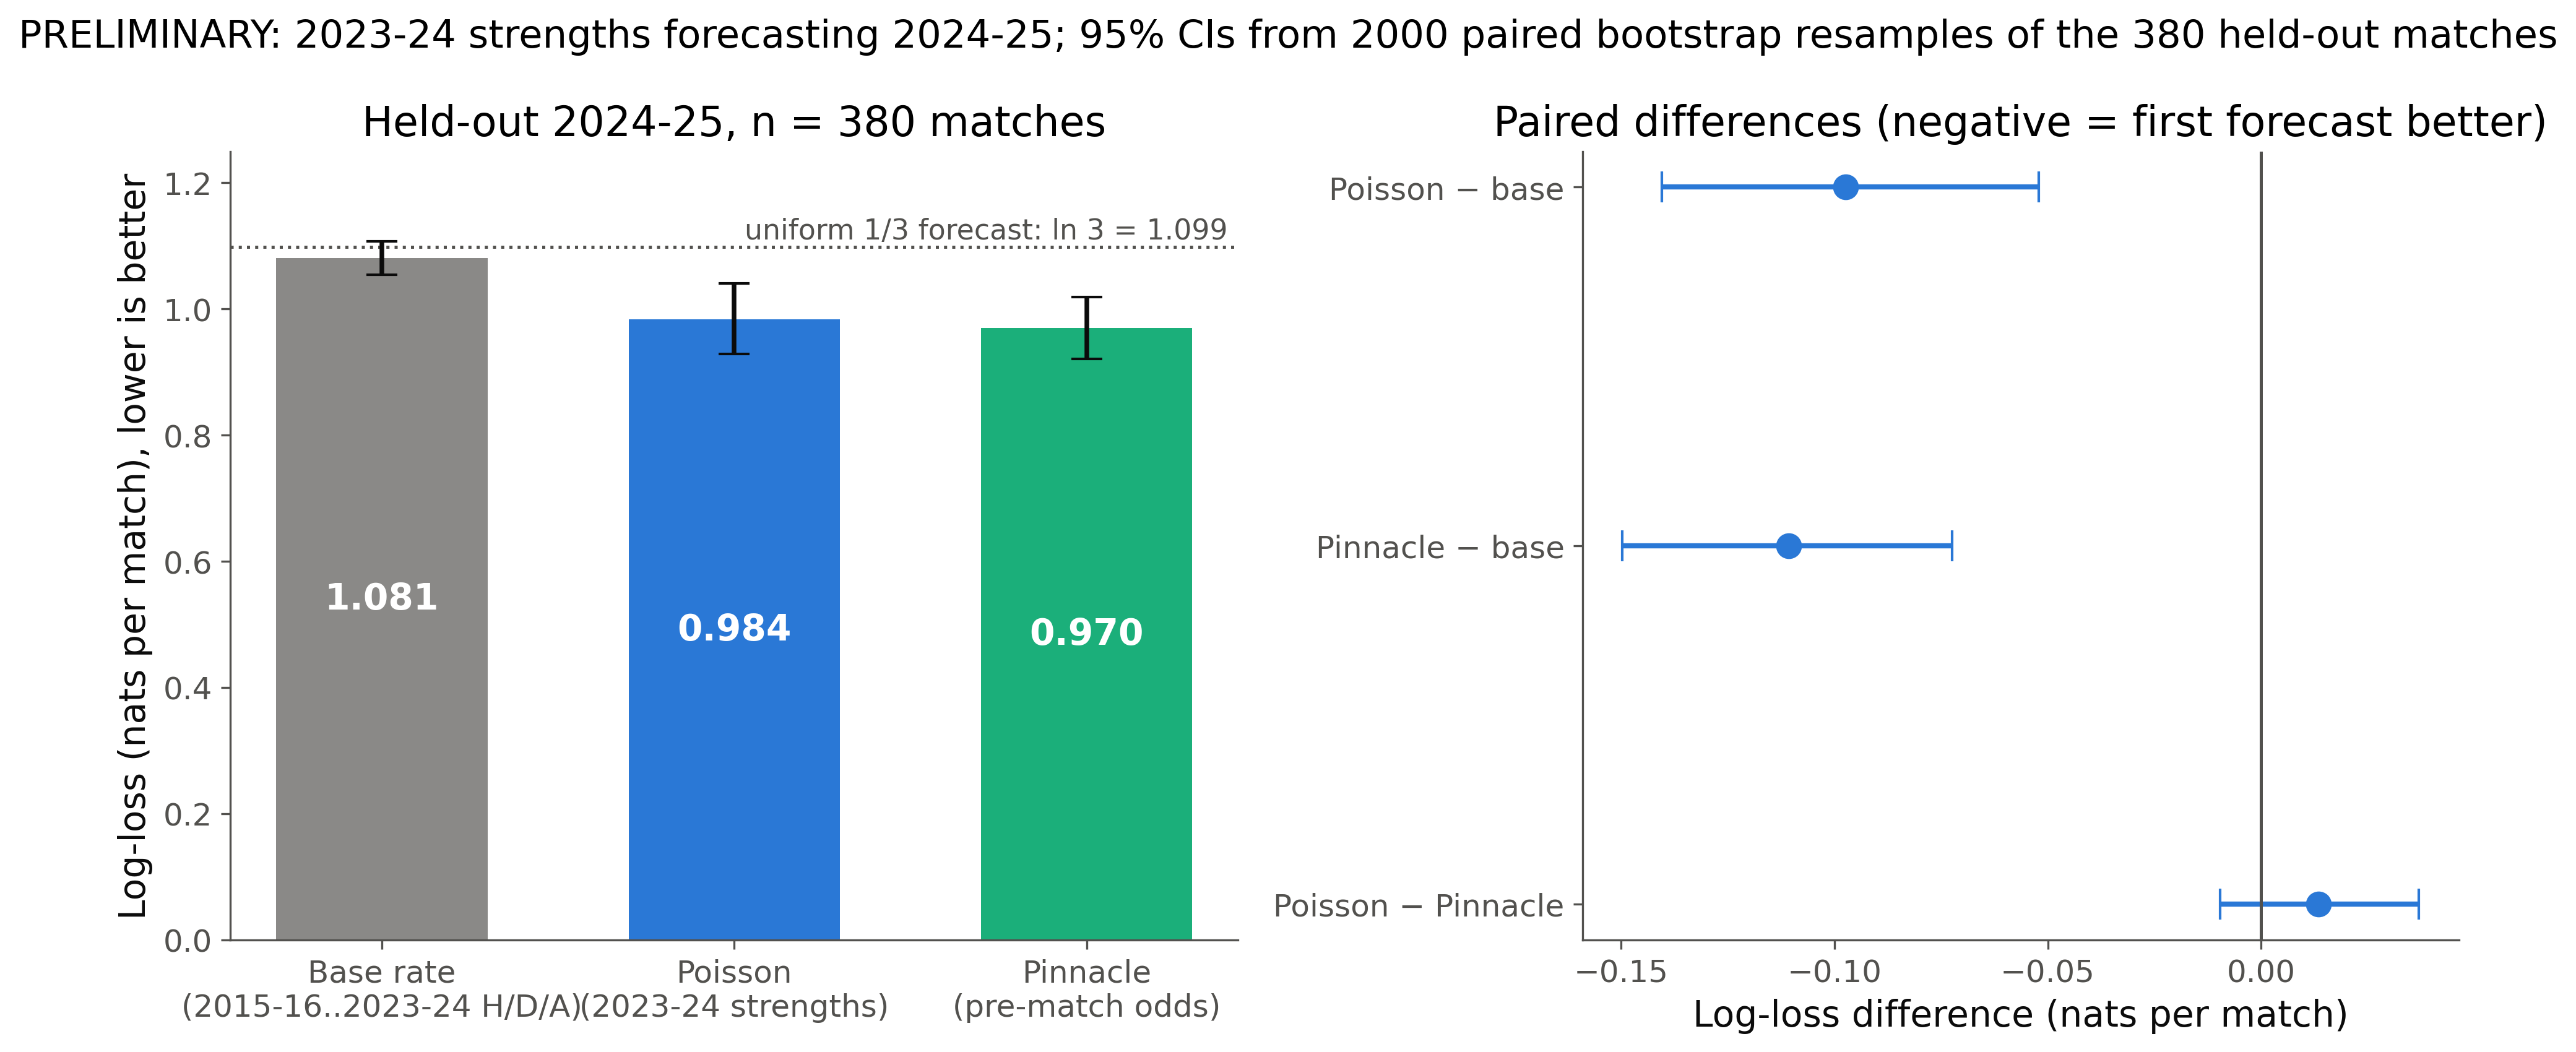

,log_loss,lo,hi,minus_poisson,diff_lo,diff_hi
forecast,,,,,,
base_rate,1.0811,1.0539,1.1070,0.0974,0.0522,0.1405
poisson,0.9837,0.9292,1.0411,0.0000,0.0000,0.0000
pinnacle,0.9703,0.9213,1.0190,-0.0134,-0.0370,0.0097
pinnacle_closing,0.9664,0.9172,1.0159,-0.0173,-0.0422,0.0059


In [17]:
fs = R.frozen_split_forecast(core, "2023-24", "2024-25")
oi = fs["outcome_idx"]
ll = {k: log_loss(p, oi) for k, p in fs["probs"].items()}
bll = bootstrap_metrics(fs["probs"], oi, log_loss, n_boot=2000, seed=SEED)
assert abs(ll["poisson"] - NUM["preliminary"]["log_loss"]["poisson"]) < 1e-12
split = R.split_table(ll, bll)
R.show_figure(R.fig5_from_split(ll, bll, len(oi), 2000))
split

Figure 5: held-out log-loss of the base rate, the Poisson model and Pinnacle (left) and paired
differences (right; negative = first forecast better). The table under the figure gives each forecaster
and its paired difference from Poisson.

In [18]:
R.show_md(R.md_validation(split))

- Held-out 2024-25 log-loss (nats per match, 95% paired-bootstrap CI over the test matches): base rate 1.0811 [1.0539, 1.1070], Poisson 0.9837 [0.9292, 1.0411], Pinnacle pre-match 0.9703 [0.9213, 1.0190].
- Base rate − Poisson +0.0974 [+0.0522, +0.1405]: the model beats the no-model baseline on the same metric. Pinnacle − Poisson -0.0134 [-0.0370, +0.0097]: one season cannot tell the model and the market apart.
- These intervals treat the 2023-24 parameters as fixed (only test matches are resampled); the rolling evaluation in 6.2 adds parameter uncertainty.

### 6.2 Rolling-origin evaluation, 2016-17 to 2025-26

Before each matchday window (Fri–Mon or Tue–Thu, the moments football-data records Pinnacle's pre-match odds), refit on every earlier match since 2005-06 with exponential time decay, forecast the window, and score it against the prior-seasons base rate and Pinnacle pre-match and closing odds (workstream A, `scripts/run_rolling.py`, `results/rolling.json`). Half-life grid {none, 730, 365, 180 days}, one γ vs season-specific γ, three promoted-team rules. 2025-26 has Pinnacle odds for 210 of 380 matches, so Pinnacle comparisons use those 210 (3,630 matches over 10 seasons) and Poisson vs base rate uses all 3,800. This is the main validation; the single split above is a stand-in.

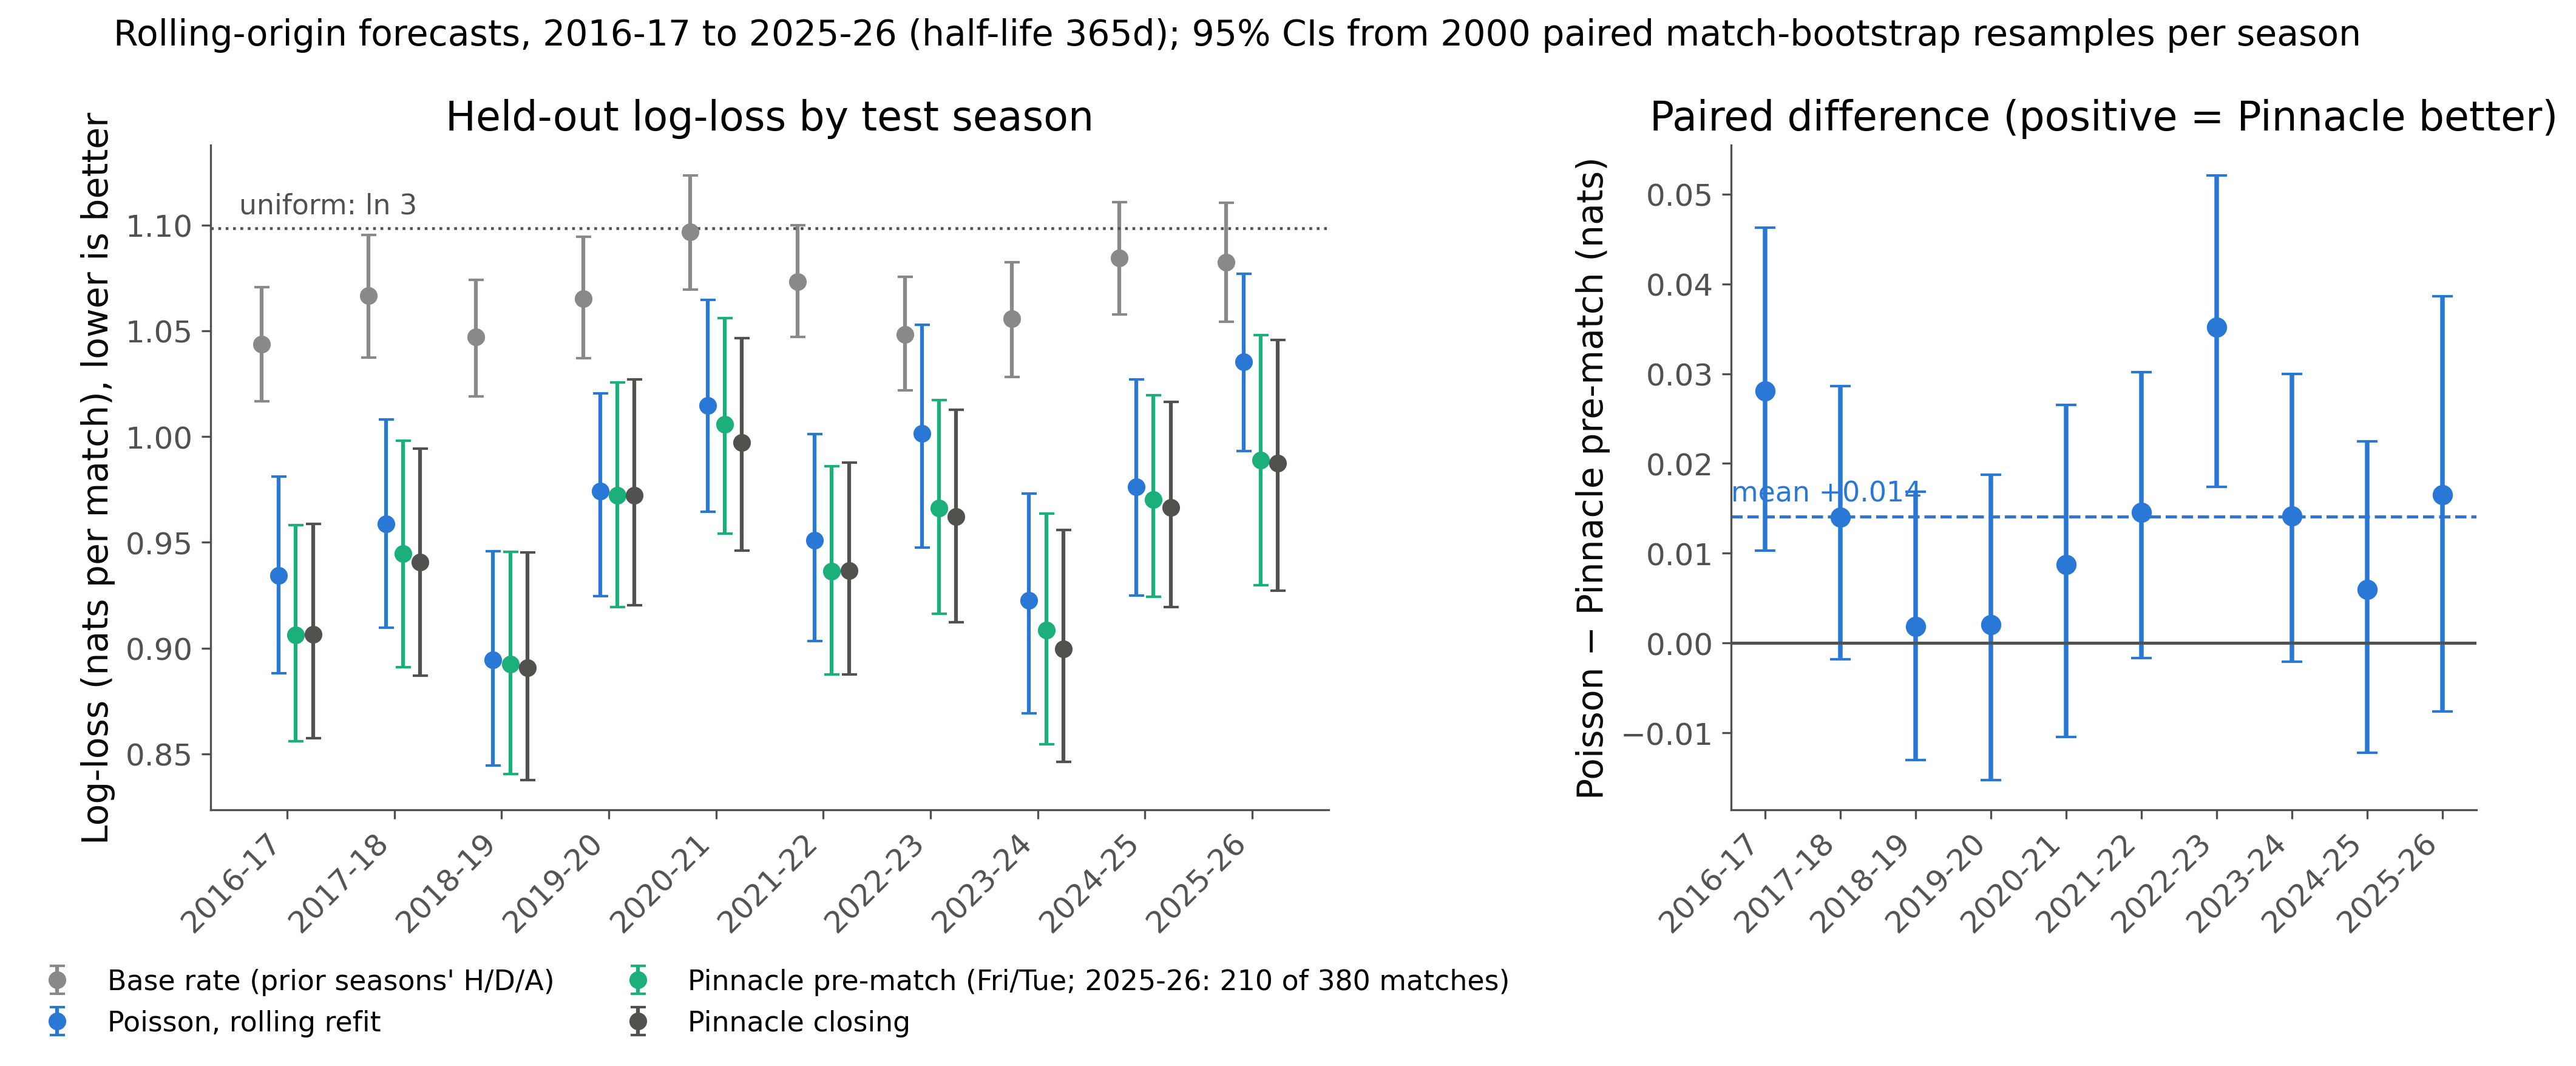

In [19]:
R.show_figure_or_placeholder(R.fig6_from_results(ROOT), "scripts/run_rolling.py")

Figure 6: held-out log-loss per test season for the base rate, the rolling Poisson model, Pinnacle pre-match and Pinnacle closing, with 95% paired match-bootstrap intervals (left), and the paired Poisson − Pinnacle pre-match difference per season with its mean (right). The model beats the base rate in every season and is behind Pinnacle in every season; one season cannot resolve the gap, ten can.

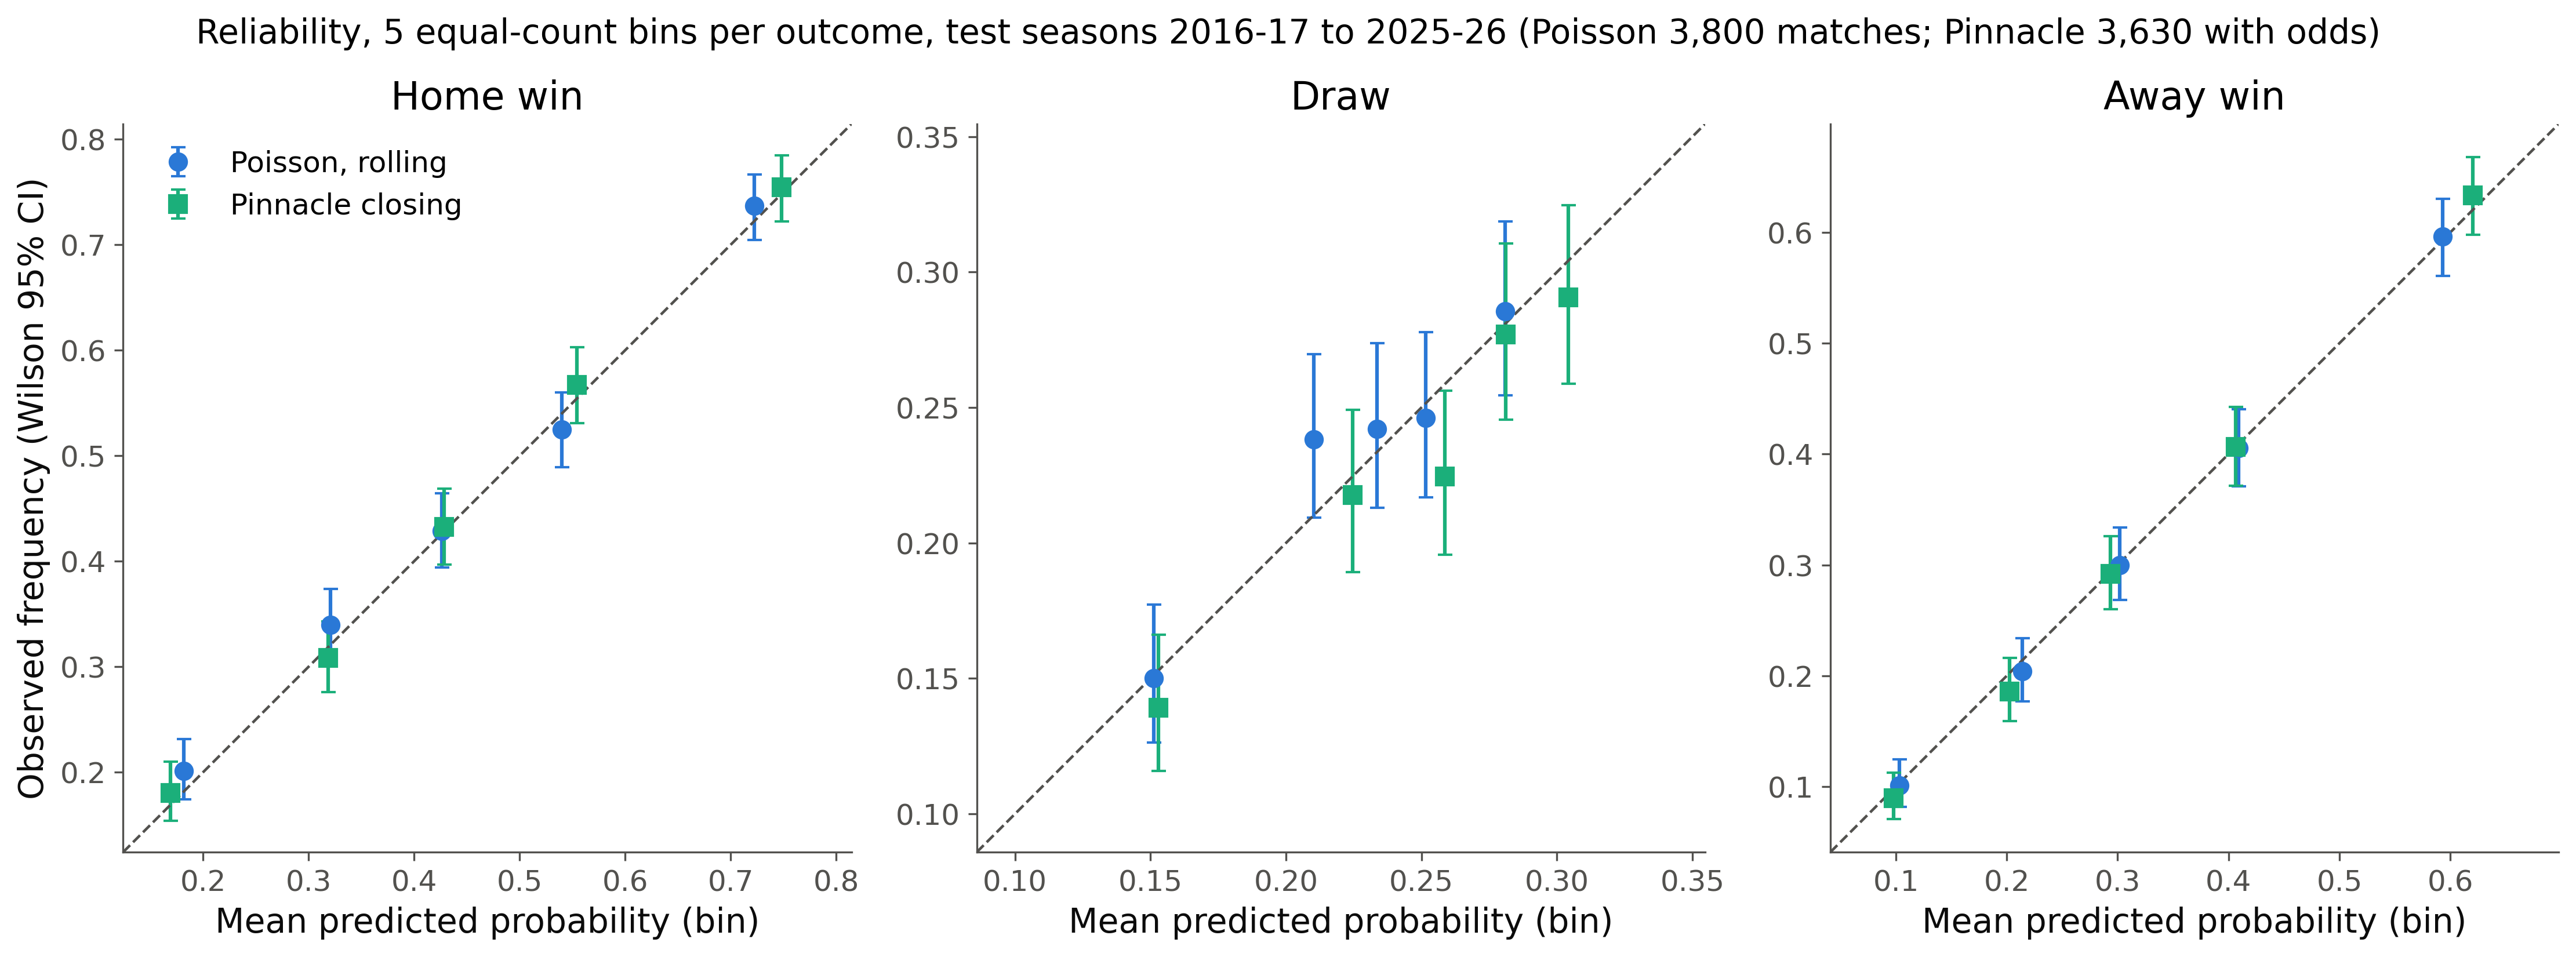

In [20]:
R.show_figure_or_placeholder(R.fig7_from_results(ROOT), "scripts/run_rolling.py")

Figure 7: reliability, five equal-count bins per outcome, rolling Poisson vs Pinnacle closing, observed frequency with Wilson 95% intervals against the mean predicted probability. Every bin of both forecasters has its mean prediction inside the observed interval. The headline numbers (estimate, 95% interval, n, how obtained):

In [21]:
R.show_md(R.results_section(ROOT, "rolling"))

**results/rolling.json (written by scripts/run_rolling.py)**  
seed 115, generated 2026-10-13T16:57:34, runtime 2025.0 s, bootstrap replicates {'eval_per_season': 2000, 'param_training_bootstrap': 200, 'betting': 2000}. Rolling-origin evaluation of the independent-Poisson model, test seasons 2016-17..2025-26. Before every Fri-Mon or Tue-Thu matchday window, refit on all earlier matches since 2005-06 with exponential time decay; team strengths per spell (consecutive PL seasons); promoted spells get a Gaussian prior (SD 0.3 on log scale) toward a rule-based target. Probabilities from the renormalised 0..10 score grid. Base rate = H/D/A frequencies over all seasons before the test season. Pinnacle 'pre-match' odds are football-data's Fri/Tue-afternoon collection (1-3 days before kick-off), not opening odds; the bookmaker knows injuries and team news the model does not. 2025-26 has Pinnacle odds for 210 of 380 matches (none after 17 Jan 2026); Pinnacle comparisons use those 210, Poisson vs base rate uses all 380.

| quantity | estimate | 95% CI | n | how obtained |
|---|---|---|---|---|
| logloss_poisson_mean10 | 0.9662 | [0.9506, 0.9822] | 3800 | rolling Poisson (hl=365d\|gamma=season\|promoted=relegated), refitted before every Fri-Mon / Tue-Thu window; mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| logloss_base_rate_mean10 | 1.0663 | [1.0574, 1.0749] | 3800 | H/D/A frequencies of all seasons before the test season (from 2005-06); mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| logloss_pinnacle_prematch_mean10 | 0.9491 | [0.9333, 0.9660] | 3630 | Pinnacle pre-match (Fri/Tue collection, 1-3 days before kick-off), margin removed proportionally; Pinnacle and the paired Poisson values use the 3,630 matches with odds (2025-26: 210 of 380); mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| logloss_pinnacle_closing_mean10 | 0.9459 | [0.9302, 0.9629] | 3630 | Pinnacle closing odds, margin removed proportionally; Pinnacle and the paired Poisson values use the 3,630 matches with odds (2025-26: 210 of 380); mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| logloss_poisson_on_odds_matches_mean10 | 0.9632 | [0.9479, 0.9799] | 3630 | same Poisson forecasts restricted to matches with Pinnacle odds; mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| brier_poisson_mean10 | 0.5736 | [0.5628, 0.5847] | 3800 | multi-class Brier (0..2); mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| brier_base_rate_mean10 | 0.6450 | [0.6387, 0.6511] | 3800 | multi-class Brier (0..2); mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| brier_pinnacle_prematch_mean10 | 0.5616 | [0.5504, 0.5733] | 3630 | multi-class Brier; Pinnacle and the paired Poisson values use the 3,630 matches with odds (2025-26: 210 of 380); mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| poisson_minus_base_logloss_mean10 | -0.1001 | [-0.1140, -0.0867] | 3800 | paired difference (negative = Poisson better), all 3,800 matches; mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| poisson_minus_pinnacle_prematch_logloss_mean10 | 0.0141 | [0.0083, 0.0195] | 3630 | paired difference (positive = Pinnacle better); Pinnacle and the paired Poisson values use the 3,630 matches with odds (2025-26: 210 of 380); mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| poisson_minus_pinnacle_prematch_logloss_mean10_seasons_as_units | 0.0141 | [0.0064, 0.0218] | 10 | same mean, CI = t interval over the 10 per-season differences (treats seasons as the sampling unit) |
| poisson_minus_pinnacle_closing_logloss_mean10 | 0.0173 | [0.0114, 0.0229] | 3630 | paired difference vs Pinnacle closing; Pinnacle and the paired Poisson values use the 3,630 matches with odds (2025-26: 210 of 380); mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| poisson_minus_pinnacle_between_season_sd | 0.0107 | [0.0074, 0.0196] | 10 | SD of the 10 per-season Poisson - Pinnacle pre-match differences; chi-square CI; Cochran Q = 13.4 on 9 df (p = 0.15) against the per-season bootstrap SEs |
| poisson_minus_pinnacle_detectable_gap_per_season | 0.0249 | [0.0208, 0.0322] | 10 | 2.80 x per-season paired bootstrap SE (5% two-sided test, 80% power); est = mean over seasons, 'ci' = range over the 10 seasons (a design quantity, not a confidence interval); mean SE = 0.0089 |
| poisson_minus_pinnacle_detectable_gap_10_seasons | 0.0079 | [0.0079, 0.0079] | 10 | 2.80 x SE of the 10-season mean difference, SE = sqrt(sum SE_s^2)/10; exact design quantity, no interval |
| seasons_poisson_beats_pinnacle_prematch | 0.0000 | [0.0000, 0.0000] | 10 | count of test seasons with Poisson - Pinnacle pre-match < 0 (point estimate; none is significant on its own unless its CI excludes 0); 'ci' = binomial 2.5/97.5% quantiles at the observed share |
| best_half_life_days | 365.0000 | [180.0000, 365.0000] | 3800 | half-life (null = no decay) with the lowest mean log-loss over the 10 test seasons among 4 x 2 configs; selected on the test seasons themselves. Best on the first five seasons: hl=365d\|gamma=season\|promoted=relegated; on the last five: hl=365d\|gamma=one\|promoted=relegated. 'ci' = shortest and longest half-life (days) whose paired log-loss difference from the best has a 95% CI including 0 (same gamma mode; no decay within: False) |
| decay_gain_vs_no_decay | 0.0159 | [0.0097, 0.0221] | 3800 | paired log-loss difference no decay - best half-life (positive = decay helps), all 3,800 test matches; 2000 paired match-bootstrap replicates |
| season_gamma_minus_one_gamma | -0.0003 | [-0.0014, 0.0010] | 3800 | paired log-loss difference season-specific gamma - one gamma at the best half-life (negative = season gamma better); 2000 paired match-bootstrap replicates |
| promoted_rule_range_all_matches | 0.0006 | [-0.0002, 0.0015] | 3800 | log-loss of the worst rule (league_avg) - best rule (shrink50) over all 3,800 test matches; paired bootstrap, 2000 replicates; rules: mean of relegated / league average / 50% shrink; prior SD 0.3 on log scale |
| promoted_rule_range_promoted_matches | 0.0021 | [-0.0009, 0.0052] | 1080 | same difference on the 1080 test matches involving a promoted team; paired bootstrap |
| logloss_2024_25_match_only | 0.9763 | [0.9248, 1.0270] | 380 | rolling Poisson (hl=365d\|gamma=season\|promoted=relegated); parameters treated as fixed, 2000 resamples of the 380 test matches |
| logloss_2024_25_param_and_match | 0.9763 | [0.9402, 1.0435] | 380 | 200 replicates: resample every season up to 2024-25 with replacement (within season), redo all 45 rolling refits incl. the promoted-team targets, score the resampled test matches; percentile CI. Includes parameter, imputation and match sampling uncertainty; width ratio to match-only = 1.01 |
| logloss_2024_25_param_only_sd | 0.0081 | [0.9601, 0.9934] | 380 | SD over the training-set bootstrap of the log-loss on the fixed 380 test matches (parameter + imputation only); 'ci' is the percentile interval of that log-loss re-centred on the point estimate |
| citl_home_mean10 | -0.0039 | [-0.0183, 0.0109] | 3800 | mean predicted P(home) - realised home share, rolling Poisson; mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| citl_draw_mean10 | -0.0029 | [-0.0166, 0.0104] | 3800 | mean predicted P(draw) - realised draw share; mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| citl_away_mean10 | 0.0069 | [-0.0068, 0.0202] | 3800 | mean predicted P(away) - realised away share; mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| citl_draw_pinnacle_closing_mean10 | 0.0096 | [-0.0040, 0.0236] | 3630 | same for Pinnacle closing, Pinnacle and the paired Poisson values use the 3,630 matches with odds (2025-26: 210 of 380) |
| home_goals_pred_minus_realised_mean10 | -0.0028 | [-0.0424, 0.0375] | 3800 | mean lambda - mean home goals; mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| away_goals_pred_minus_realised_mean10 | -0.0204 | [-0.0568, 0.0150] | 3800 | mean mu - mean away goals; mean over the 10 test seasons of the per-season mean log-loss (nats/match); 95% CI from 2000 match-resampling bootstrap replicates per season, averaged across seasons replicate by replicate |
| home_goals_pred_minus_realised_2024_25_rolling | 0.0943 | [-0.0271, 0.2156] | 380 | rolling mean lambda 1.607 vs realised 1.513; match bootstrap |
| home_goals_pred_minus_realised_2024_25_frozen | 0.2867 | [0.1578, 0.4157] | 380 | frozen 2023-24 fit from results/numbers.json 'preliminary': mean lambda 1.800 vs realised 1.513; CI from 2000 resamples of the 380 matches' home goals (lambda fixed) |
| betting_return_margin_0pct | 0.0678 | [-0.0533, 0.1916] | 689 | flat 1-unit bets at Pinnacle closing odds when p_model * odds - 1 > 0.00, 2024-25 and 2025-26 (590 matches with odds); return per unit staked; 2000 match-resampling bootstrap replicates |
| betting_return_margin_5pct | 0.0147 | [-0.1212, 0.1641] | 552 | flat 1-unit bets at Pinnacle closing odds when p_model * odds - 1 > 0.05, 2024-25 and 2025-26 (590 matches with odds); return per unit staked; 2000 match-resampling bootstrap replicates |
| betting_return_margin_10pct | 0.0341 | [-0.1342, 0.1998] | 433 | flat 1-unit bets at Pinnacle closing odds when p_model * odds - 1 > 0.10, 2024-25 and 2025-26 (590 matches with odds); return per unit staked; 2000 match-resampling bootstrap replicates |

### 6.3 Goodness of fit and the Dixon–Coles correction

The fit checks use all 11 seasons pooled (season-specific strengths, one γ), not one season. First the
goal histograms against the fitted Poisson mixture, with a parametric-bootstrap band: 2,000 data sets
of 4,180 matches simulated from the fitted rates (no refit, which makes the band slightly wide;
seed 115 + 303 so the figure matches `scripts/run_dixon_coles.py`).

envelope seed = 418


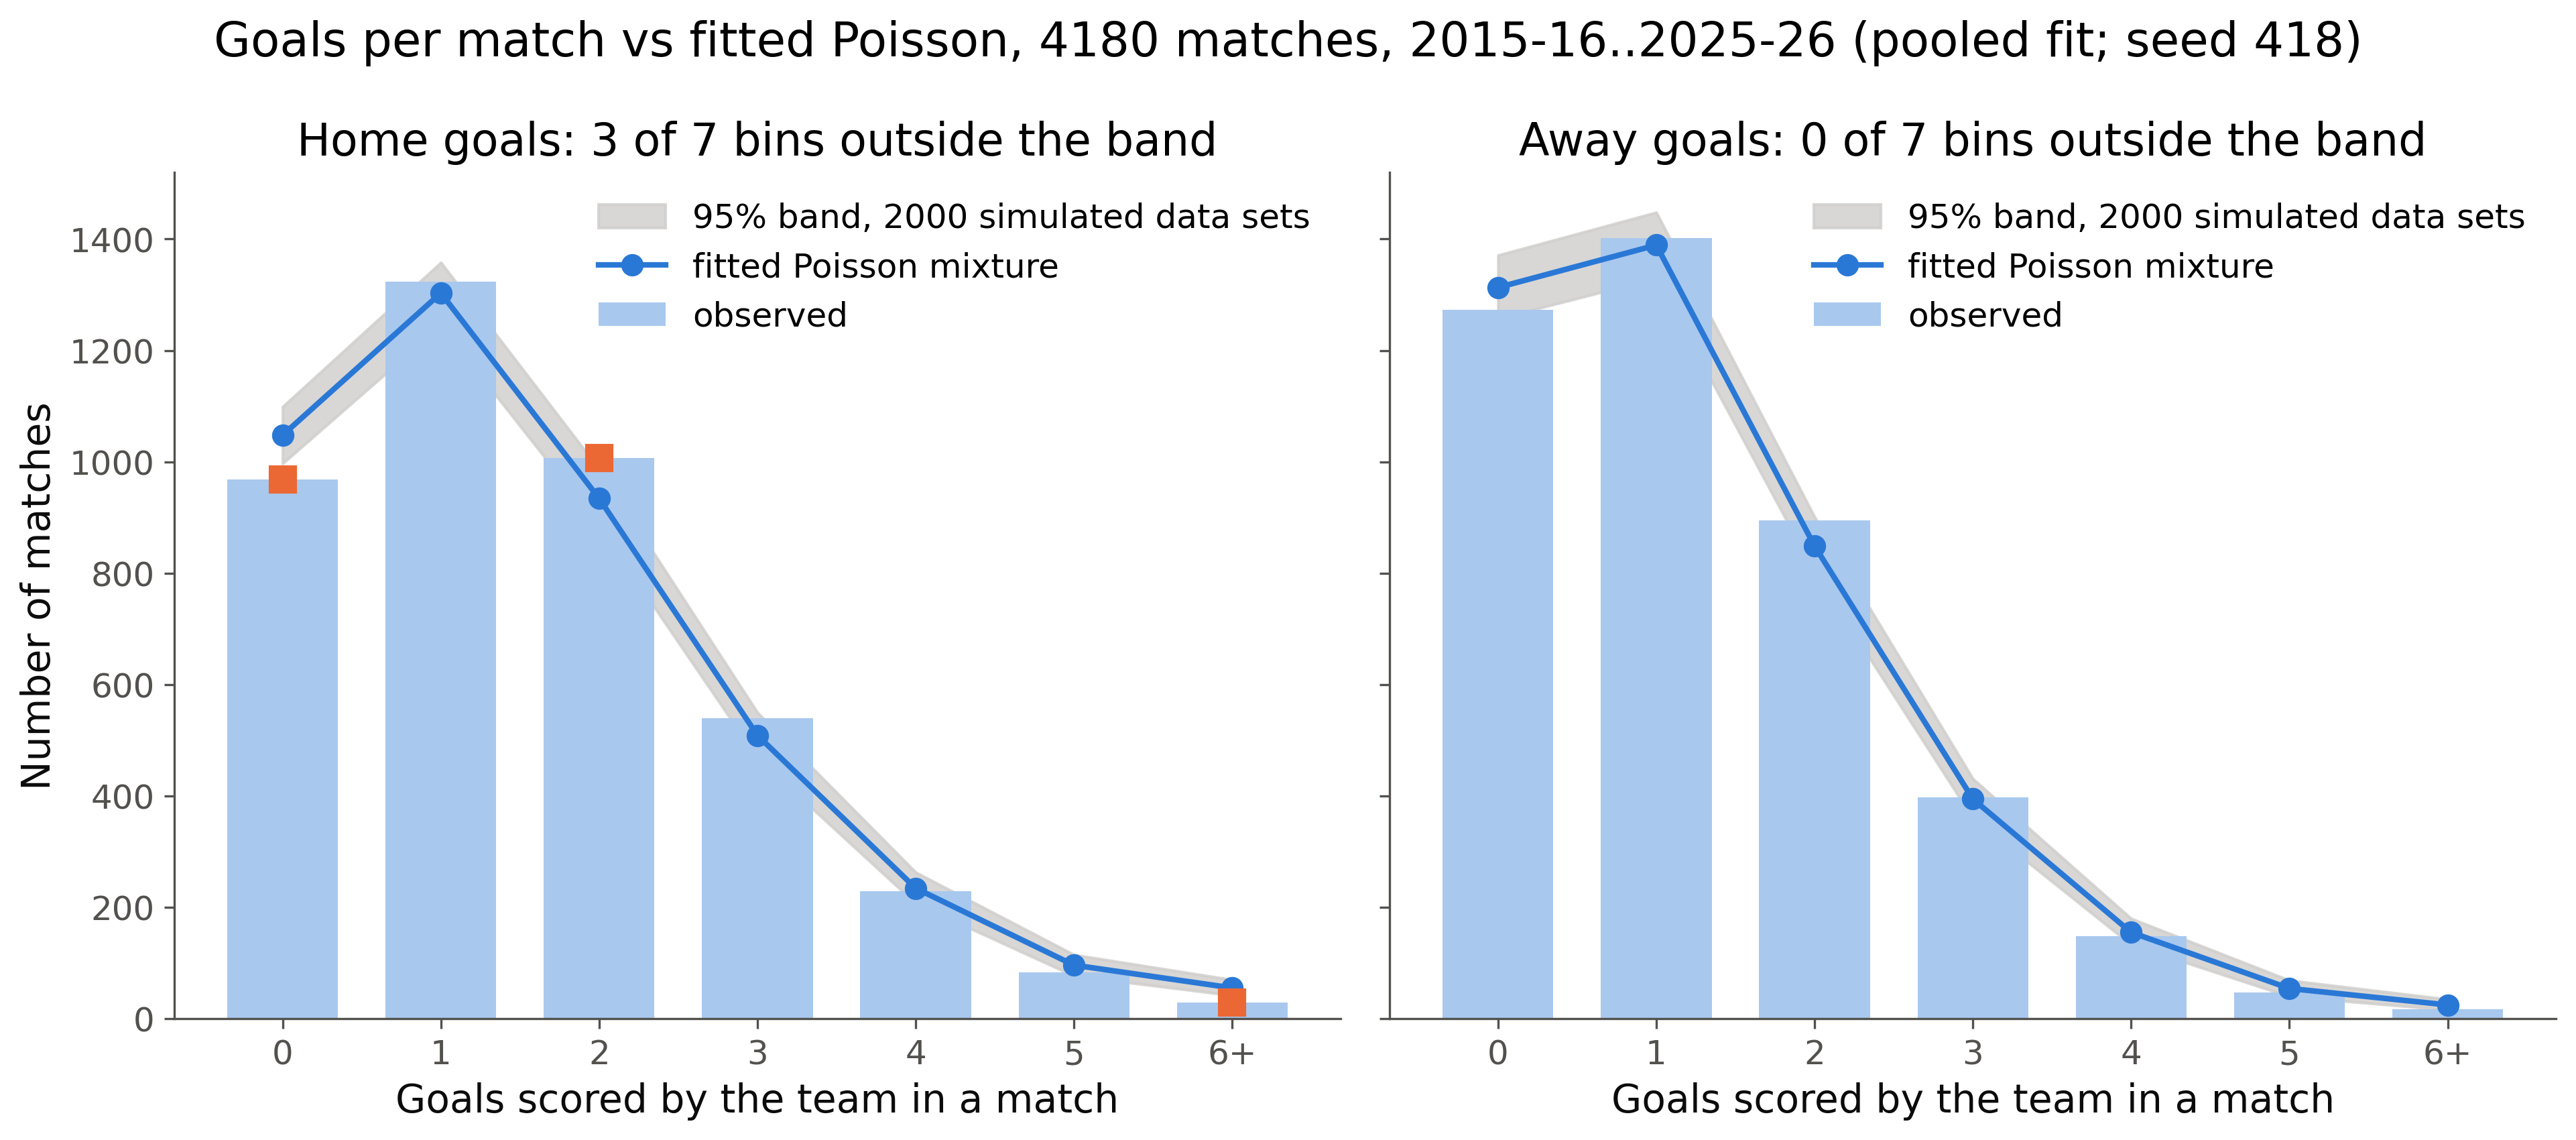

In [22]:
dp = make_design(core, season="season")
fpp = fit_poisson(dp)
fdp = DC.fit_dixon_coles(dp, poisson_fit=fpp)
lam_p, mu_p = rates(fpp.log_alpha, fpp.log_beta, fpp.log_gamma, dp.home, dp.away)
env = DC.goal_histogram_envelope(dp.x, dp.y, lam_p, mu_p, 2000, np.random.default_rng(SEED + 303))
print(f"envelope seed = {SEED + 303}")
R.show_figure(DC.fig3_goals_envelope(env, title_extra=f", 2015-16..2025-26 (pooled fit; seed {SEED + 303})"))

Figure 3: observed goals per match (bars), the fitted Poisson mixture (line) and its 95% band (grey);
orange squares are bins outside the band. Away goals sit inside the band; home goals have too few
0s and 6+ and too many 2s: home scoring is less variable than Poisson. The dispersion numbers in section 2
say the same. This replaces the old variance-vs-mean caption, which was not a dispersion test.

Then the scoreline table: observed counts in the 16 cells 0..3 × 0..3 and "4+", expected under the
pooled Poisson and pooled Dixon–Coles fits, and Pearson residuals (obs − exp)/√exp.

In [23]:
lam_d, mu_d = fdp.rates(dp)
sc = DC.scoreline_table(dp.x, dp.y, lam_p, mu_p, lam_d, mu_d, fdp.rho)
print(f"pooled rho-hat = {fdp.rho:+.4f}, admissible range [{fdp.admissible[0]:+.3f}, {fdp.admissible[1]:+.3f}], converged = {fdp.converged}")
sc

pooled rho-hat = -0.0507, admissible range [-0.226, +0.214], converged = True


,scoreline,observed,expected_poisson,pearson_poisson,expected_dc,pearson_dc
0,0-0,263,283.1273,-1.1962,305.2506,-2.4183
1,0-1,292,337.7719,-2.4905,315.9679,-1.3484
2,0-2,215,229.8679,-0.9806,229.8604,-0.9802
3,0-3,121,117.7716,0.2975,117.7545,0.2991
4,1-0,370,389.6348,-0.9947,367.9603,0.1063
5,1-1,455,431.4819,1.1322,453.3202,0.0789
6,1-2,293,272.9006,1.2167,272.7598,1.2255
7,1-3,125,130.0869,-0.4460,129.9849,-0.4372
8,2-0,317,305.8343,0.6385,306.0118,0.6281
9,2-1,340,314.9204,1.4133,314.8610,1.4167


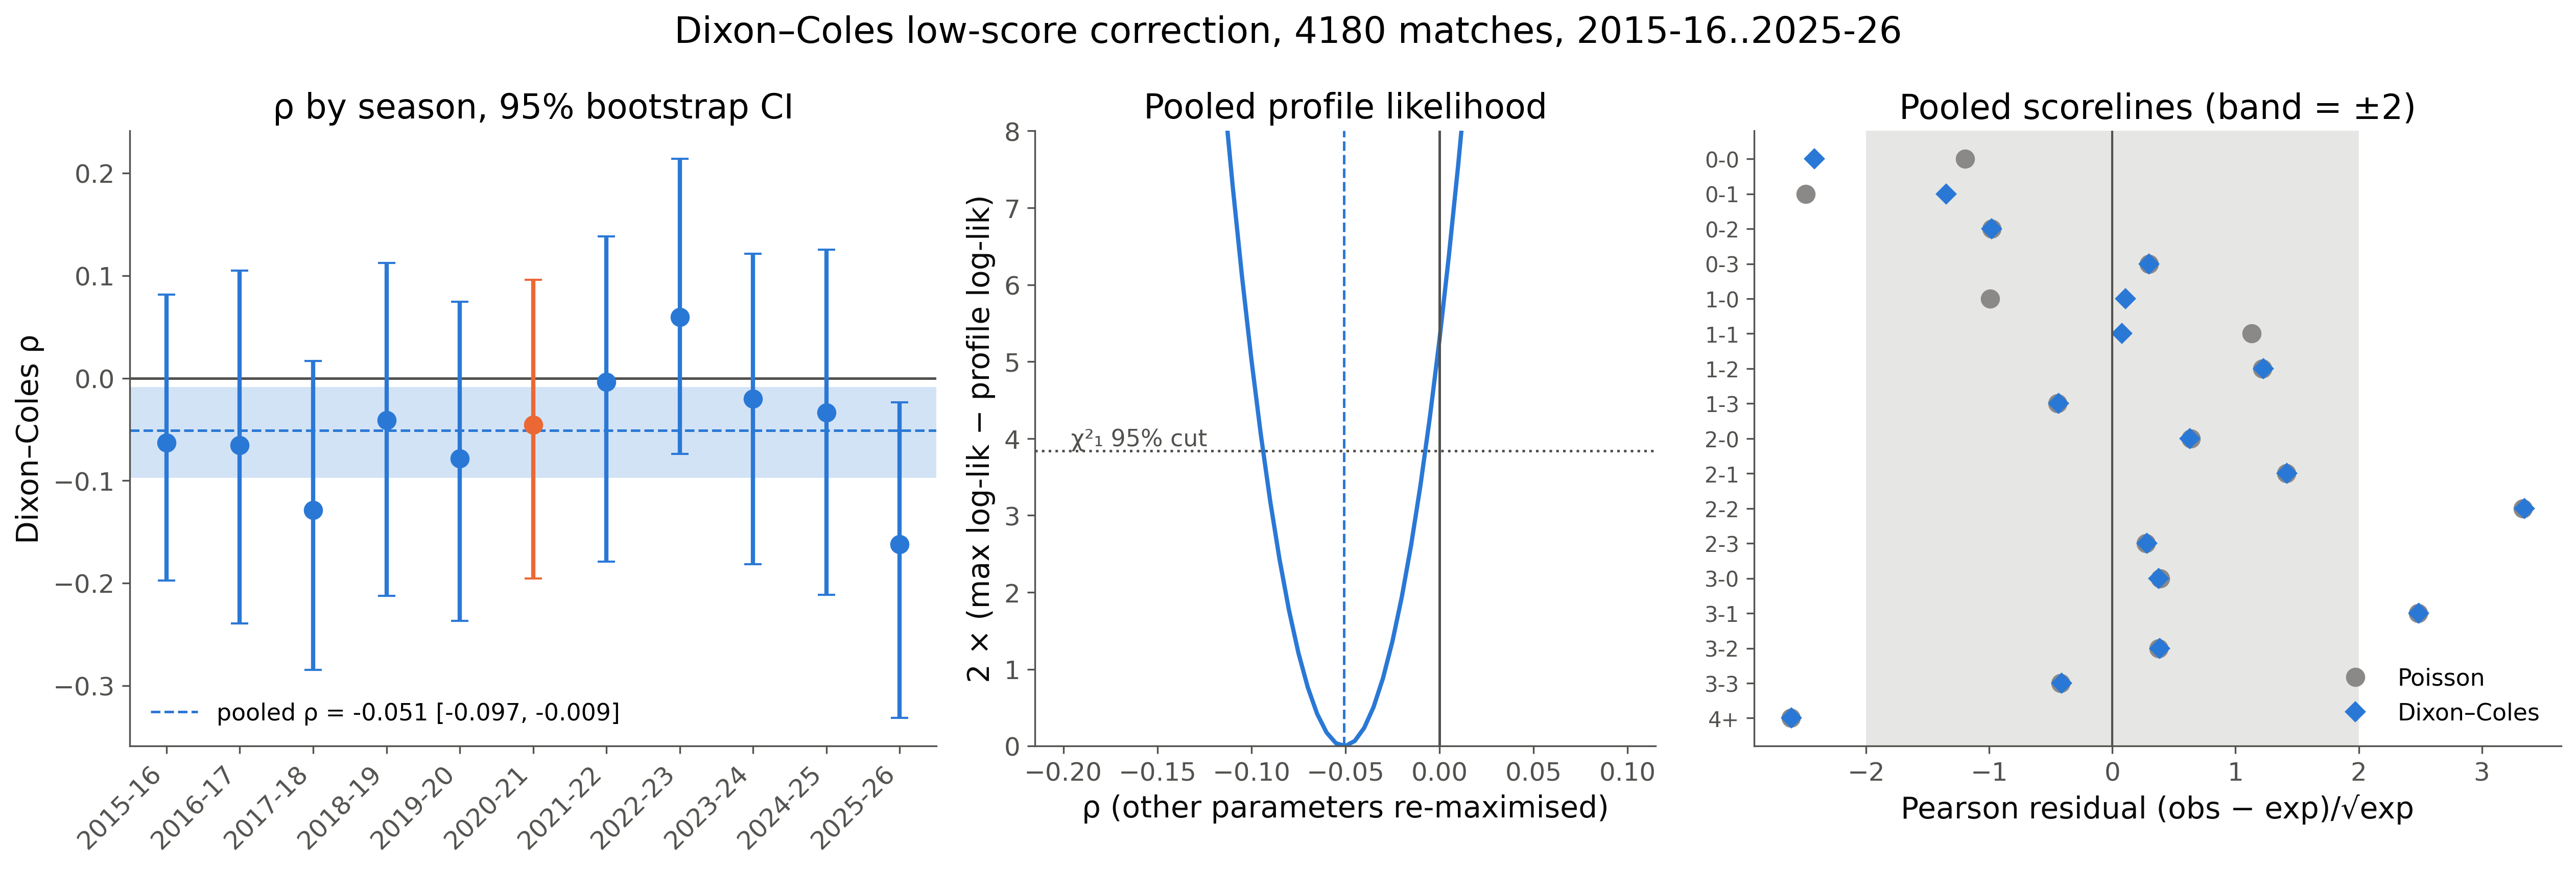

In [24]:
grid = np.array(DCR["details"]["pooled"]["profile"]["rho_grid"])
prof = DC.profile_loglik(dp, grid, fdp)
R.show_figure(DC.fig9_dixon_coles(DC_SEASON, DCR["headline"]["pooled_rho"], grid, prof, sc), width=1000)

Figure 9: (left) ρ̂ by season with 1,000-replicate bootstrap intervals (read from
`results/dixon_coles_by_season.csv`) and the pooled estimate; (middle) the pooled profile likelihood,
recomputed live, whose crossing of the χ²₁ line gives a likelihood-ratio interval; (right) Pearson
residuals of the pooled scoreline table under both models.

The correction is small and its sign is the textbook one, but it does not fix what is wrong: ρ < 0
*raises* the 0-0 count, which Poisson already over-predicts, while it fixes 1-1 and 1-0. The cells
that miss most (2-2, 3-1 too many; 0-1 and 4+ too few) are outside the four cells τ touches. Its effect
on forecasts, recomputed live on the 2024-25 split:

In [25]:
p_dc, rho23 = R.heldout_dc_probs(fs)
sets = {"poisson": fs["probs"]["poisson"], "dixon_coles": p_dc}
ll_dc = {k: log_loss(p, oi) for k, p in sets.items()}
bll_dc = bootstrap_metrics(sets, oi, log_loss, n_boot=2000, seed=SEED)
assert abs(ll_dc["dixon_coles"] - DCR["headline"]["heldout_logloss_dc"]["est"]) < 1e-10
R.show_md(R.md_dixon_coles(DCR, ll_dc, bll_dc, rho23))

- Pooled ρ̂ = -0.051 [-0.097, -0.009] (joint MLE over 11 seasons (season-specific alpha, beta; one gamma; one rho; 431 params), 95% percentile CI from 1000 season-stratified match-resampling refits (seed 415); profile-likelihood CI [-0.0937, -0.0075]).
- LR test of ρ = 0: statistic 5.27 on 1 df, p = 0.022 (χ²₁ reference); scoreline log-likelihood gain 2.64 nats over 4180 matches.
- 0-0: observed 263, Poisson expects 283.1, Dixon–Coles 305.3 (95% simulation range of obs − exp under Poisson [-31.1, +30.9]). 1-1: observed 455, Poisson 431.5, Dixon–Coles 453.3.
- Largest pooled Pearson residual: +3.33 [-1.88, +2.01] (largest |(obs-exp)/sqrt(exp)| of the 17 pooled cells (0..3 x 0..3, 4+) under the pooled Poisson fit, cell 2-2; 4 of 17 cells exceed 2; ci = 95% range of that cell's residual in 2000 data sets simulated from the fit (seed 416, no refit); P(max |r| >= observed | model) = 0.009).
- In-sample outcome log-loss change, DC − Poisson: -0.00074 [-0.00151, +0.00004] nats per match, -3.11 [-6.31, +0.15] nats in total over 11 seasons (paired bootstrap).
- Held-out 2024-25, recomputed live (DC on 2023-24, ρ̂ = -0.020): DC − Poisson -0.00078 [-0.00180, +0.00025] nats per match (paired bootstrap, seed 115); with ρ pooled over 2015-16..2023-24 instead: -0.00150 [-0.00354, +0.00052].
- **In one line:** the correction moves log-loss by about a thousandth of a nat per match (-0.0008 [-0.0018, +0.0002] held out, -0.0007 [-0.0015, +0.0000] in sample).

All Dixon–Coles headline numbers, with how each was obtained (`results/dixon_coles.json`):

In [26]:
R.show_md(R.results_section(ROOT, "dixon_coles"))

**results/dixon_coles.json (written by scripts/run_dixon_coles.py)**  
seed 115, generated 2026-10-13T16:23:48, runtime 60.5 s, bootstrap replicates 1000. Dixon-Coles rho per season and pooled (season-specific strengths, one gamma, one rho), LR test of rho = 0, pooled 11-season scoreline table with Pearson residuals, goal-histogram envelope, in-sample and held-out (2023-24 -> 2024-25) log-loss with and without the correction.

| quantity | estimate | 95% CI | n | how obtained |
|---|---|---|---|---|
| pooled_rho | -0.0507 | [-0.0974, -0.0086] | 4180 | joint MLE over 11 seasons (season-specific alpha, beta; one gamma; one rho; 431 params), 95% percentile CI from 1000 season-stratified match-resampling refits (seed 415); profile-likelihood CI [-0.0937, -0.0075] |
| pooled_lr_statistic | 5.2749 | [0.0010, 5.0239] | 4180 | 2 x (loglik DC - loglik Poisson) for the pooled fit, 1 df; p = 0.0216; ci = central 95% range of chi2_1 under rho = 0 (not a CI of the statistic) |
| pooled_loglik_gain_nats | 2.6374 | [0.0005, 2.5119] | 4180 | scoreline log-likelihood gain of the pooled DC fit over the pooled Poisson fit, total nats; ci = central 95% range of the gain under rho = 0 (chi2_1 / 2) |
| max_abs_pearson_residual_poisson | 3.3341 | [-1.8777, 2.0128] | 4180 | largest \|(obs-exp)/sqrt(exp)\| of the 17 pooled cells (0..3 x 0..3, 4+) under the pooled Poisson fit, cell 2-2; 4 of 17 cells exceed 2; ci = 95% range of that cell's residual in 2000 data sets simulated from the fit (seed 416, no refit); P(max \|r\| >= observed \| model) = 0.009 |
| max_abs_pearson_residual_dc | 3.3447 | [-1.8689, 2.0964] | 4180 | same under the pooled Dixon-Coles fit, cell 2-2; 4 of 17 cells exceed 2; ci from 2000 DC simulations (seed 417); P(max \|r\| >= observed \| DC) = 0.008 |
| observed_minus_expected_0_0_poisson | -20.1273 | [-31.1273, 30.8977] | 4180 | 0-0 count observed 263 minus expected 283.1 under the pooled Poisson fit (DC expects 305.3); ci = 95% range of obs - exp in 2000 simulated data sets (seed 416) |
| pearson_dispersion_pooled | 0.9481 | [0.9691, 1.0314] | 8360 | sum of squared Pearson residuals of home and away goals / (2m - p), pooled Poisson fit; ci = 95% range under the Poisson model (chi2_7930/7930); per-season values 0.880..1.090 in dixon_coles_by_season.csv |
| goal_histogram_bins_outside_band | 3.0000 | [0.0000, 14.0000] | 4180 | bins (0..6+, home and away, 14 total) where the observed count lies outside the 95% parametric-bootstrap band (2000 simulated data sets from the pooled Poisson fit, seed 418); ci field = possible range |
| insample_logloss_change_per_match | -0.0007 | [-0.0015, 0.0000] | 4180 | outcome (H/D/A) log-loss of the pooled DC fit minus the pooled Poisson fit over all 4180 matches, nats per match (negative = DC better); paired bootstrap of matches, 2000 resamples, seed 115, no refit |
| insample_logloss_change_total_nats | -3.1094 | [-6.3097, 0.1473] | 4180 | the per-match change times the number of matches (total nats over 11 seasons); same bootstrap |
| heldout_logloss_poisson | 0.9837 | [0.9292, 1.0411] | 380 | 2023-24 Poisson strengths frozen, promoted = mean of relegated, normalised 0..10 grid (reproduces numbers.json preliminary.log_loss.poisson); paired bootstrap of the 380 test matches, 2000 resamples, seed 115 |
| heldout_logloss_dc | 0.9830 | [0.9292, 1.0400] | 380 | Dixon-Coles fitted jointly on 2023-24 only (rho = -0.0201), same freezing and promoted rule; same paired bootstrap |
| heldout_logloss_dc_minus_poisson | -0.0008 | [-0.0018, 0.0002] | 380 | paired log-loss difference, DC fitted on 2023-24 minus Poisson, nats per match on 2024-25 (negative = DC better); 2000 paired resamples, seed 115 |
| heldout_logloss_dc_prior_rho_minus_poisson | -0.0015 | [-0.0035, 0.0005] | 380 | paired log-loss difference, Poisson 2023-24 strengths with rho pooled over 2015-16..2023-24 (rho = -0.0399) minus Poisson, nats per match on 2024-25 (negative = DC better); 2000 paired resamples, seed 115 |
| heldout_logloss_dc_minus_pinnacle | 0.0127 | [-0.0100, 0.0364] | 380 | paired difference DC (2023-24) minus Pinnacle pre-match (Fri/Tue collection) on 2024-25; same bootstrap |

## 7. What changed after section

Each item of the Milestone 2 feedback and of the three critique streams of 13 October, taken up or set aside with a reason. The numbers are read from the results files of sections 4–6.

In [27]:
R.show_md(R.md_what_changed(ROOT, NUM))

**Milestone 2 feedback.** The written comment on the M2 presentation (Andrew Cheng, Canvas) was: *"Great presentation! Simple benchmarks would be appreciated."* The brief for the final adds three requirements the M2 version only partly met: a held-out forecast compared with a model-free baseline and the betting market, an error bar on every number with how it was obtained, and a check of the code against known mathematics. The M2 submission had one frozen split marked PRELIMINARY, a bootstrap on the 380 test matches only, and a Skellam check. All four were taken up:

- *"Simple benchmarks would be appreciated"* → taken up: every forecast in section 6 is scored on the same metric against two benchmarks that need no model, the uniform forecast (1/3 each, log-loss ln 3 = 1.0986 nats per match in every season) and the prior-seasons base rate (1.0663 [1.0574, 1.0749] over the 10 test seasons), and against the market (Pinnacle pre-match 0.9491 [0.9333, 0.9660], closing 0.9459 [0.9302, 0.9629]); the Poisson model sits at 0.9662 [0.9506, 0.9822]. Figures 5 and 6 show the benchmarks side by side with the model.
- *Held-out validation with a baseline* → taken up: rolling-origin evaluation over 10 test seasons (section 6.2), Poisson − base rate -0.1001 [-0.1140, -0.0867] and Poisson − Pinnacle pre-match +0.0141 [+0.0083, +0.0195] nats per match.
- *Error bars on everything* → taken up: every number in this report carries a 95% interval and the way it was obtained; the 2024-25 interval now includes parameter and imputation uncertainty (0.9763 [0.9402, 1.0435] vs match-only 0.9763 [0.9248, 1.0270]).
- *Verification against known mathematics* → taken up: the analytic solution γ̂ = ΣH/ΣA holds to 3.5e-07 in all 21 seasons (section 5), and the bootstrap intervals cover the true γ with probability 0.948 [0.925, 0.966] on simulated seasons.

**Three critique streams on the M2 version** (13 October: an assumptions critique, an estimation-and-uncertainty review, and two validation checks). Taken up:

- The held-out base rate used all 11 seasons including the test season, and the Poisson probabilities were the raw 0..10 grid mass. Fixed; the before/after table below shows the 2024-25 Poisson − base difference moving from -0.0965 to -0.0974 (both with their paired-bootstrap intervals).
- Pinnacle's non-closing odds were labelled "opening"; they are pre-match odds collected 1–3 days before kick-off (football-data notes), so the bookmaker knows team news the model never sees. Relabelled everywhere.
- One bootstrap seed was reused for every season; now 115 + season index, recorded in every output.
- The Fig 5 right-panel title, the duplicated home-advantage figure (γ and extra goals are one finding, by the identity), and the variance-vs-mean caption that was not a dispersion test: fixed; the dispersion is now a Pearson statistic (0.948 [0.969, 1.031] pooled, Poisson range in the interval column).
- "One γ for all seasons": the LR test (p = 0.0163) and Cochran's Q (p = 0.1732) disagreed because one included 2020-21 and the other did not. Reconciled in section 4; over 2005-06..2025-26 a common γ is rejected even without 2020-21 (Q p = 0.0064) because home advantage declines by about 9% per decade.
- Crowd status is a match-level condition (92 restart matches in 2019-20; limited crowds in Dec 2020 and May 2021): flagged by date in section 4, with the statement that attendance is not in the data.
- The frozen fit's 1.80-vs-1.51 goal miscalibration: the rolling fit reduces it to +0.094 [-0.027, +0.216] goals per match from +0.287 [+0.158, +0.416] (section 6.2).
- Dixon–Coles was fitted rather than assumed: ρ = -0.051 [-0.097, -0.009], and it moves held-out log-loss by -0.0008 [-0.0018, +0.0002] nats per match (section 6.3).
- Warm-started recovery refits, no boundary or gradient check, 500 replicates for 2.5% tails: a cold-start run, max |θ| and projected-gradient norms, and 2,000-replicate intervals are reported in sections 4 and 5.

Set aside, with reasons:

- Recovery and coverage under a misspecified data-generating process (over-dispersion, correlated goals, drifting strengths): not done for time; section 8 says what it would show.
- A full random-effects or time-series model for γ: the DerSimonian–Laird τ, a linear trend and the z-scores under three reference models answer the question with three numbers; a model would add parameters we cannot validate on 21 points.
- Raw-file hashes and the run date in the fixture test: the AM115 standard grades the notebook, not the repository; the raw files are committed instead.
- A separate validation period for choosing the half-life: the choice is reported as made on the test seasons, with a first-five / last-five split as the check (section 6.2).
- The brief's second identifiability constraint (geometric mean of β = 1): set aside with the likelihood evidence in section 3 (it is over-constrained, 24 nats worse in 2023-24).

Before/after table for the single-split numbers of section 6.1 (the two shared fixes: base rate from pre-test seasons only, probabilities renormalised on the grid):

In [28]:
R.show_md(R.md_before_after(NUM))

| quantity (2024-25, nats per match) | before 13 Oct fixes | after |
|---|---|---|
| base-rate log-loss | 1.0803 [1.0545, 1.1048] (11 seasons incl. test) | 1.0811 [1.0539, 1.1070] (pre-test seasons only) |
| Poisson log-loss | 0.9838 [0.9293, 1.0412] (raw grid) | 0.9837 [0.9292, 1.0411] (renormalised) |
| Poisson − base | -0.0965 [-0.1398, -0.0513] | -0.0974 [-0.1405, -0.0522] |

All intervals: 95% paired bootstrap over the 380 test matches (2000 resamples, seed 115, run_all.py).

## 8. What this does not show

Each limit below is stated with the number that shows it (read from the results files).

In [29]:
R.show_md(R.md_not_shown(ROOT))

- **The data cannot decide that crowds cause home advantage.** The closed-door evidence is 2020-21 (γ = 1.008 [0.884, 1.143]) plus 92 restart matches in 2019-20; there is no attendance variable, only a date flag. Within 2019-20..2021-22, closed doors minus full crowds is -0.108 [-0.247, +0.040], an interval that includes 0, and the 92 restart matches show ordinary home advantage (+0.074 [-0.140, +0.304] vs full crowds). The Bundesliga (-0.091 [-0.247, +0.059]) and La Liga (-0.190 [-0.339, -0.031]) point the same way, but their partial-crowd dates were not separated.
- **2024-25 is as unusual as 2020-21, with full stadiums.** γ = 1.065 [0.956, 1.187]; under random effects its z is -3.03 [-4.99, -1.07] against -2.82 [-4.78, -0.86] for 2020-21 (z ± 1.96 in the brackets). A single low season is therefore not evidence of a crowd effect; the question "was 2020-21 lower" has the answer yes, the question "because of the crowds" does not.
- **Home advantage is not a constant.** Over 2005-06..2025-26 it falls by -0.0099 [-0.0142, -0.0055] in log γ per season (about 9% per decade), so the common-γ interval is an average over a declining series. Why it declines is not something these data say.
- **The model is behind the market by a small, now measurable, margin.** Poisson − Pinnacle pre-match is +0.0141 [+0.0083, +0.0195] nats per match over 10 seasons (detectable gap in one season 0.025, range over seasons 0.021–0.032; over ten seasons 0.0079, a design quantity); the single 2024-25 split could not tell them apart, ten seasons can. Part of the gap is information (team news) the model never sees, and the data cannot say how much. The betting test (+6.8% [-5.3%, +19.2%] at margin 0 on 590 matches) has no power either way.
- **The independent-Poisson scoreline model misfits in ways Dixon–Coles does not repair.** The largest pooled Pearson residual is 3.33 [-1.88, 2.01] (cell 2-2; the bracket is that cell's range under the model), four of 17 cells exceed 2, and home goals are under-dispersed (dispersion 0.948 [0.969, 1.031], bracket = Poisson range). ρ = -0.051 [-0.097, -0.009] moves held-out log-loss by -0.0008 [-0.0018, +0.0002] nats per match: the outcome forecasts are insensitive to the scoreline misfit.
- **The error bars are validated only under the model.** Coverage 0.948 [0.925, 0.966] is for simulated Poisson seasons; the date-block interval for 2020-21 is narrower than the iid one (0.219 [0.212, 0.226] vs 0.260 [0.252, 0.268], Monte Carlo ranges) and the team-cluster one wider (0.304 [0.295, 0.314] in 2024-25), so an iid interval could be understated by up to about a third if home-team clustering matters.
- **What another month would buy:** coverage and recovery under a misspecified data-generating process (over-dispersed or correlated goals, strengths that drift within a season); the same crowd-flag analysis with verified attendance for all three leagues; a within-season update of strengths in the forecast that uses team news; and a bivariate or under-dispersed count model for the scorelines.

## 9. Contribution statement

- **Alexander van Poecke**: the question and assumptions (sections 1, 2); the model identity γ̂ = ΣH/ΣA and its use as
  the verification check (sections 3, 5); home advantage over 2005-06..2025-26 with the common-γ tests, the crowd flag by
  date and the Bundesliga / La Liga comparison, the date-block and team-cluster bootstraps, the CI-coverage and
  cold-start studies and the fit diagnostics (sections 4, 5: `src/timeseries.py`, `src/crowd.py`,
  `scripts/run_timeseries.py`, `tests/test_timeseries.py`, `figures/fig2_home_advantage_2005_2026`,
  `figures/fig8_crowd_gamma`, `review/results_timeseries.md`); the fixes shared by all workstreams (`run_all.py`,
  `src/model.py`, `src/data.py`, `tests/test_data.py`); sections 7 and 8; integration of this notebook
  (`src/report.py` sections 7–8 helpers, `results/SUMMARY.md`, `README.md`).
- **David Domanski**: the rolling-origin forecast evaluation with time decay, team spells and the promoted-team rules;
  the calibration-in-the-large and reliability tables; the training-set bootstrap that puts parameter and imputation
  uncertainty into the 2024-25 interval; the betting test (section 6.2: `src/rolling.py`, `scripts/run_rolling.py`,
  `tests/test_rolling.py`, `figures/fig6_rolling_logloss`, `figures/fig7_rolling_reliability`,
  `review/results_rolling.md`); the single-split base-rate and normalisation fixes (section 6.1).
- **Alexia Potter**: the Dixon–Coles correction with its bootstrap, profile likelihood and likelihood-ratio test; the pooled
  scoreline table with Pearson residuals and the goal-histogram envelope (sections 3, 6.3: `src/dixon_coles.py`,
  `scripts/run_dixon_coles.py`, `tests/test_dixon_coles.py`, `figures/fig3_goals_envelope`, `figures/fig9_dixon_coles`,
  `review/results_dixon_coles.md`); figure styling (`src/figures.py`); this notebook and its helper module
  `src/report.py` (the notebook standard: functions in `src/`, every figure from the cell above it, `rng` with the seed
  printed).

Each person's code runs from `scripts/run_<name>.py` and writes `results/<name>.json`; every number in this notebook
is rendered from those files or recomputed by the same functions.
